# CSE 4460 — Big Data Analytics Lab
## Open-Ended Experiment: Big Data Analysis of Urban Bus Mobility

**Student Name:** _<your name>_ &nbsp;&nbsp;|&nbsp;&nbsp; **Student ID:** _<your id>_
&nbsp;&nbsp;|&nbsp;&nbsp; **Section:** 03 &nbsp;&nbsp;|&nbsp;&nbsp; **Semester:** Summer 2026

---

### Analytical question

> **When and where does New York City bus service peak, how much service quality does
> corridor congestion destroy at those peaks, and can individual route-segment-hours be
> compressed into a small number of latent operating regimes that make unusual bus
> behaviour visible?**

### Dataset

**MTA Bus Route Segment Speeds, 2023–2024** (NY State Open Data, `58t6-89vi`) —
**11,656,097 records**, 20 attributes, **356 bus routes**, **2,794 timepoint stops**,
6 boroughs. Each record is one *route segment* (timepoint stop → next timepoint stop)
observed in one *clock hour*, carrying the segment length, the mean bus travel time
across it, the mean road speed, and how many bus trips were observed.

A second, much larger feed — **MTA Bus Hourly Ridership** (`kv7t-n8in`,
**447 million** source rows) — is aggregated *server-side* into a passenger-demand
table and joined on route, so that service supply and passenger demand can be read
against each other.

### How this notebook maps to the marked tasks

| Task | Marks | Where |
|---|---|---|
| 1. Big Data environment & architecture | 10 | §1–§2 |
| 2. Conceptual Big Data architecture (volume / velocity / variety) | 10 | §3 |
| 3. Preprocessing, analysis & visualisation | 20 | §4–§8 |

> **Runtime:** ~20–30 minutes end to end on a free Colab CPU runtime, of which
> ~8–12 minutes is the parallel download of the 11.7 M-record feed.
> Run the cells in order (`Runtime ▸ Run all`).
>
> **In a hurry?** Set `YEARS = [2024]` in §1.3 — that halves both the download
> and the processing time and still leaves ~5.8 M records.

---
# 1. Setting up the Big Data environment  *(Task 1)*

A pinned JDK and a pinned Spark build so the notebook is deterministic rather than
dependent on whatever image Colab is serving today.

In [ ]:
# --- JDK 17 + Spark 3.5.1 (a combination Spark officially supports) --------
!apt-get -qq install -y openjdk-17-jre-headless > /dev/null 2>&1
!pip install -q pyspark==3.5.1

import os, glob
_jdk = glob.glob("/usr/lib/jvm/java-17-openjdk-*")
if _jdk:
    os.environ["JAVA_HOME"] = _jdk[0]
!java -version

In [ ]:
import hashlib, json, math, time, urllib.parse, urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pacsv
import pyarrow.parquet as pq
import matplotlib
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA, VectorSlicer
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.stat import Correlation
from pyspark.ml.functions import vector_to_array

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "grid.alpha": 0.3,
})
PALETTE = {"primary": "#1f4e79", "secondary": "#e07b39", "accent": "#2e8b57",
           "warn": "#c0392b", "muted": "#8b95a1"}
print("libraries ready")

### 1.1 The Spark pseudo-cluster

Every setting below is tuned away from its default for a stated reason — an
untuned `SparkSession` on a single node spends most of its time scheduling
work rather than doing it.

In [ ]:
APP = "CSE4460-OEL-NYC-Bus-BigData"

spark = (
    SparkSession.builder.appName(APP).master("local[*]")
    # memory / parallelism
    .config("spark.driver.memory", "8g")
    .config("spark.sql.shuffle.partitions", "64")
    # Adaptive Query Execution: re-plan shuffles from runtime statistics
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.sql.adaptive.skewJoin.enabled", "true")
    # columnar / vectorised I/O
    .config("spark.sql.parquet.compression.codec", "snappy")
    .config("spark.sql.parquet.enableVectorizedReader", "true")
    .config("spark.sql.parquet.filterPushdown", "true")
    # zero-copy Spark <-> pandas hand-off for plotting
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
    # The MTA publishes `timestamp` as a naive local-time hour stamp, already in
    # NYC wall-clock. Pinning the session to UTC makes Spark surface the stored
    # value verbatim, with no implicit shift -- skipping this silently rotates
    # every peak-hour conclusion in the report.
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.parquet.inferTimestampNTZ.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
rt = sc._jvm.java.lang.Runtime.getRuntime()

ENV = {
    "spark_version": spark.version,
    "java_version": sc._jvm.System.getProperty("java.version"),
    "master": sc.master,
    "cores": rt.availableProcessors(),
    "driver_heap_mb": round(rt.maxMemory() / 1e6),
    "default_parallelism": sc.defaultParallelism,
}
for k, v in ENV.items():
    print(f"{k:22}: {v}")

### 1.2 Storage architecture — a medallion data lake

The same logical layout an HDFS or S3 deployment would use, here on the Colab disk:

| Layer | Contents | Guarantee |
|---|---|---|
| **Bronze** | raw MTA records, one Parquet file per month, exactly as the API served them | immutable, never edited — any bug is always re-playable |
| **Silver** | cleaned, conformed, feature-enriched segment-hours, partitioned by month | one canonical schema, zero nulls, every row physically plausible |
| **Gold** | small aggregated marts (hour × weekday supply, corridor rankings, regime profiles) | cheap to query, safe to hand to a dashboard |

### 1.3 Ingestion: a parallel, resumable pull from the Socrata API

The MTA does not publish this feed as a single downloadable file — it is served
record-by-record through the Socrata (SODA) REST API. Pulling 11.7 M records
serially takes roughly half an hour, so the loader below does what an ingestion
tier actually does:

* **partitions the request by month**, giving 24 independent, idempotent chunks
  (rather than `$offset` paging, whose cost grows with depth and which silently
  skews if the underlying table is re-sorted);
* **runs the chunks through a thread pool**, overlapping network wait;
* **retries with exponential back-off**, because a public API will drop requests;
* **is resumable** — a chunk already on disk is skipped, so a disconnected
  runtime costs only the chunks that were in flight;
* **converts each chunk CSV → Parquet and deletes the CSV**, so the Bronze layer
  lands columnar and peak disk stays bounded;
* **records a provenance manifest** (URL, bytes, rows, SHA-256) per chunk.

In [ ]:
ROOT   = Path("/content/oel_bus")
BRONZE = ROOT / "bronze"; SILVER = ROOT / "silver"; GOLD = ROOT / "gold"
for d in (BRONZE, SILVER, GOLD):
    d.mkdir(parents=True, exist_ok=True)

# --- dataset 58t6-89vi : MTA Bus Route Segment Speeds, 2023-2024 -----------
DOMAIN     = "https://data.ny.gov"
SEGMENT_ID = "58t6-89vi"
RIDERSHIP_ID = "kv7t-n8in"

YEARS   = [2023, 2024]          # <- set to [2024] for a half-length run
MONTHS  = [(y, m) for y in YEARS for m in range(1, 13)]
WORKERS = 6
LIMIT   = 700000     # biggest month is 531,353 rows

# Only the columns the experiment uses. The two GeoJSON blobs the API also
# carries are ~40% of the payload and duplicate the lat/lon pairs, so asking
# for a projection here is the first (and cheapest) optimisation in the whole
# pipeline: it is column pruning pushed all the way back to the source system.
COLS = ["timestamp", "day_of_week", "hour_of_day", "route_id", "direction",
        "borough", "route_type", "stop_order",
        "timepoint_stop_id", "timepoint_stop_name",
        "timepoint_stop_latitude", "timepoint_stop_longitude",
        "next_timepoint_stop_id", "next_timepoint_stop_name",
        "next_timepoint_stop_latitude", "next_timepoint_stop_longitude",
        "road_distance", "average_travel_time", "average_road_speed",
        "bus_trip_count"]

def chunk_url(year, month):
    q = {"$select": ",".join(COLS),
         "$where": f"year={year} AND month={month}",
         "$order": "timestamp",
         "$limit": LIMIT}
    return f"{DOMAIN}/resource/{SEGMENT_ID}.csv?" + urllib.parse.urlencode(q, safe="$,:")

print(f"{len(MONTHS)} monthly chunks, {WORKERS} parallel workers")
print(chunk_url(*MONTHS[0])[:150] + " ...")

In [ ]:
# Declared up front so pyarrow never has to guess, and so a month whose sample
# happens to hold no nulls cannot infer a different type from its neighbours --
# schema drift between partitions is the classic way a multi-file read fails
# only after the expensive stage has already run.
CSV_TYPES = {
    "timestamp": pa.timestamp("us"), "day_of_week": pa.string(),
    "hour_of_day": pa.int32(), "route_id": pa.string(), "direction": pa.string(),
    "borough": pa.string(), "route_type": pa.string(), "stop_order": pa.int32(),
    "timepoint_stop_id": pa.string(), "timepoint_stop_name": pa.string(),
    "timepoint_stop_latitude": pa.float64(), "timepoint_stop_longitude": pa.float64(),
    "next_timepoint_stop_id": pa.string(), "next_timepoint_stop_name": pa.string(),
    "next_timepoint_stop_latitude": pa.float64(),
    "next_timepoint_stop_longitude": pa.float64(),
    "road_distance": pa.float64(), "average_travel_time": pa.float64(),
    "average_road_speed": pa.float64(), "bus_trip_count": pa.int32(),
}

def fetch_chunk(ym, retries=4):
    year, month = ym
    dst = BRONZE / f"bus_segment_speeds_{year}-{month:02d}.parquet"
    if dst.exists():                       # resume: already landed
        t = pq.read_table(dst)
        return {"chunk": dst.name, "rows": t.num_rows,
                "bytes": dst.stat().st_size, "cached": True}

    url = chunk_url(year, month)
    tmp = BRONZE / f"_{year}-{month:02d}.csv"
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=900) as r, open(tmp, "wb") as f:
                while True:                # stream, never hold the body in RAM
                    buf = r.read(1 << 20)
                    if not buf:
                        break
                    f.write(buf)
            break
        except Exception as exc:
            if attempt == retries - 1:
                raise RuntimeError(f"{year}-{month:02d} failed: {exc}")
            time.sleep(2 ** attempt * 3)   # exponential back-off

    sha = hashlib.sha256(tmp.read_bytes()).hexdigest()[:16]
    tbl = pacsv.read_csv(
        tmp,
        convert_options=pacsv.ConvertOptions(column_types=CSV_TYPES),
        read_options=pacsv.ReadOptions(block_size=1 << 24),
    )
    pq.write_table(tbl, dst, compression="snappy")
    csv_bytes = tmp.stat().st_size
    tmp.unlink()                           # keep peak disk bounded
    return {"chunk": dst.name, "rows": tbl.num_rows, "bytes": dst.stat().st_size,
            "csv_bytes": csv_bytes, "sha256_16": sha, "cached": False}

In [ ]:
t0 = time.time()
MANIFEST = []
with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    for rec in ex.map(fetch_chunk, MONTHS):
        MANIFEST.append(rec)
        tag = "cached" if rec["cached"] else f"{rec.get('csv_bytes',0)/1e6:6.1f} MB csv"
        print(f"  {rec['chunk']:38} {rec['rows']:>8,} rows  "
              f"{rec['bytes']/1e6:6.1f} MB parquet  ({tag})")

BRONZE_MB = sum(r["bytes"] for r in MANIFEST) / 1e6
CSV_MB    = sum(r.get("csv_bytes", 0) for r in MANIFEST) / 1e6
N_MANIFEST = sum(r["rows"] for r in MANIFEST)
DL_SEC = time.time() - t0

(BRONZE / "_manifest.json").write_text(json.dumps(MANIFEST, indent=1))
print(f"\nBronze layer : {N_MANIFEST:,} records, {BRONZE_MB:.1f} MB Parquet "
      f"from {CSV_MB:.0f} MB of API CSV  ({CSV_MB/max(BRONZE_MB,1e-9):.1f}x compression)")
print(f"wall time    : {DL_SEC/60:.1f} min on {WORKERS} workers")

### 1.4 The second feed: passenger demand, aggregated at the source

`bus_trip_count` measures **service supply** — how many buses ran. It is not
passenger demand, and treating one as the other is the easiest mistake to make
with this dataset.

Demand comes from a separate MTA feed, *Bus Hourly Ridership*, which holds
**447 million** rows. Downloading that is neither necessary nor sensible: the
question only needs riders per route per weekday-hour, so the `GROUP BY` is
pushed to the source system and roughly 70 000 rows come back instead. This is
the same aggregate push-down principle Spark applies internally, applied one
tier further upstream.

Even push-down leaves a 447 M-row scan on the server, which takes several
minutes. That wait is **overlapped with the work Spark is about to do**: the
request is fired off on a background thread here and collected in §5.4, by
which time it has usually long finished. Overlapping I/O with compute costs one
thread and saves the entire latency.

Two robustness details worth copying into any ingestion code:

* the response is written to a `.part` file and **renamed only once complete**,
  so an interrupted run can never leave a truncated file that a later run
  mistakes for a valid cache;
* both the fetch *and* the parse are inside the failure boundary — a slow or
  throttled public API degrades the overlay in §5.4, it never stops the notebook.

In [ ]:
RIDERSHIP_CSV = BRONZE / "bus_ridership_route_dow_hour.csv"
# The scan cost scales with the window, so the overlay uses the most recent
# year in YEARS. The join in 5.4 needs the route x weekday x hour *shape*,
# which is stable year on year; widening this only makes the wait longer.
RIDER_YEAR = max(YEARS)

def fetch_ridership():
    if RIDERSHIP_CSV.exists():
        return "cached"
    q = {"$select": ("bus_route,date_extract_dow(transit_timestamp) AS dow,"
                     "date_extract_hh(transit_timestamp) AS hh,"
                     "sum(ridership) AS riders,sum(transfers) AS xfers"),
         "$where": (f"transit_timestamp >= '{RIDER_YEAR}-01-01' AND "
                    f"transit_timestamp < '{RIDER_YEAR+1}-01-01'"),
         "$group": "bus_route,dow,hh",
         "$limit": 200000}
    url = f"{DOMAIN}/resource/{RIDERSHIP_ID}.csv?" + urllib.parse.urlencode(q, safe="$,:")
    part = RIDERSHIP_CSV.with_suffix(".part")
    t0 = time.time()
    with urllib.request.urlopen(url, timeout=1800) as r, open(part, "wb") as f:
        while True:
            buf = r.read(1 << 20)
            if not buf:
                break
            f.write(buf)
    part.replace(RIDERSHIP_CSV)          # atomic: never cache a partial file
    return f"fetched in {time.time()-t0:.0f}s"

RIDER_POOL = ThreadPoolExecutor(max_workers=1)
RIDER_FUTURE = RIDER_POOL.submit(fetch_ridership)
print(f"ridership aggregate ({RIDER_YEAR}, 447 M source rows) requested on a "
      f"background thread;\ncollected in section 5.4 while Spark works.")

---
# 2. Reading the data and proving the engine is working

The plan printed below is the evidence for Task 1: Catalyst rewrites the query,
prunes to the columns actually referenced out of 20, and pushes the filters
down into the Parquet row-group footers so whole row groups are skipped
before decoding.

In [ ]:
raw = spark.read.parquet(str(BRONZE / "bus_segment_speeds_*.parquet"))

N_RAW = raw.count()
print(f"raw segment-hour records : {N_RAW:,}")
print(f"attributes               : {len(raw.columns)}")
print(f"input partitions         : {raw.rdd.getNumPartitions()}")
raw.printSchema()

In [ ]:
demo = (raw.select("timestamp", "road_distance", "average_road_speed", "route_id")
           .filter((F.col("road_distance") > 0.5) & (F.col("average_road_speed") > 0))
           .groupBy(F.hour("timestamp").alias("hour"))
           .agg(F.count("*").alias("segment_hours"),
                F.avg("average_road_speed").alias("avg_mph")))
demo.explain(mode="formatted")

In [ ]:
print("Scale of the feed:")
raw.select(
    F.countDistinct("route_id").alias("routes"),
    F.countDistinct("timepoint_stop_id").alias("timepoint_stops"),
    F.countDistinct("borough").alias("boroughs"),
    F.countDistinct("route_type").alias("route_types"),
    F.min("timestamp").alias("first_hour"),
    F.max("timestamp").alias("last_hour"),
).show(truncate=False)

print("Records by borough and service type:")
(raw.groupBy("borough").pivot("route_type").count()
    .na.fill(0).orderBy("borough").show(truncate=False))

### 2.1 What is one row, actually?

Never take a column called `timestamp` at face value. The MTA documents this
feed as *"aggregated by month, day of the week, and hour of day"*, which means
`timestamp` cannot be an event time — and the probe below shows what it really
is. Getting this wrong does not raise an error; it silently produces a
confident, wrong answer, so it is checked before anything is built on it.

In [ ]:
n_ts = raw.select("timestamp").distinct().count()
n_months = raw.select(F.date_format("timestamp", "yyyy-MM")).distinct().count()
print(f"distinct timestamps : {n_ts:,}")
print(f"distinct months     : {n_months}   ->  {n_months} months x 24 hours = {n_months*24}")

# If `timestamp` were a real date, its weekday would match `day_of_week`
# exactly. It does not: the two are independent, so `day_of_week` is a
# separate grain dimension that must be carried explicitly.
agree = (raw.select(F.date_format("timestamp", "EEEE").alias("ts_weekday"), "day_of_week")
            .withColumn("match", (F.col("ts_weekday") == F.col("day_of_week")).cast("int"))
            .agg(F.avg("match")).first()[0])
print(f"\nrows where weekday(timestamp) == day_of_week : {100*agree:.1f}%  "
      f"(chance alone would give ~14.3%)")
print("=> `timestamp` is a synthetic (year, month, hour) stamp dated to the 1st.")
print("=> the real grain is month x day_of_week x hour x route x trip-type x segment.")

TOTAL_BUS_TRIPS = raw.agg(F.sum("bus_trip_count")).first()[0]
print(f"\nbus trips summarised by the feed : {TOTAL_BUS_TRIPS/1e6:,.1f} M")

---
# 3. Conceptual Big Data architecture  *(Task 2)*

The local setup above is one point in a design space. The diagram below is the
architecture a transit authority would actually deploy, and the cell after it
maps each tier onto **volume, velocity and variety** using this experiment's
measured numbers.

In [ ]:
import matplotlib.patches as mpatches

LANES = [
    ("1  SOURCES", "heterogeneous, fleet-wide", "#dbe7f3", "#1f4e79",
     ["Bus AVL / GPS\n(30 s pings, 5 800 buses)", "Farebox & OMNY\ntap-in events",
      "GTFS &\nGTFS-Realtime feeds", "Automated passenger\ncounters (APC)",
      "Traffic signals, weather,\nroad works"], None),
    ("2  INGESTION", "batch + streaming", "#fce8d5", "#e07b39",
     ["Kafka topics\n(per-route partitioned)",
      "Airflow-orchestrated\nAPI pulls (monthly chunks)",
      "Schema Registry\n+ contract validation"], None),
    ("3  STORAGE", "medallion data lake", "#d9ecdf", "#2e8b57",
     ["BRONZE\nraw, immutable, append-only", "SILVER\ncleaned, conformed, enriched",
      "GOLD\naggregated marts & features"],
     "HDFS / S3  -  Parquet + Snappy  -  partitioned by month & borough  -  Hive metastore catalogue"),
    ("4  PROCESSING", "one engine, two speeds", "#e4dcf0", "#6b4fa0",
     ["Spark Structured Streaming\nlive headway & corridor speed",
      "Spark SQL (batch)\nCatalyst + AQE + Tungsten",
      "Spark MLlib\nStandardScaler -> PCA -> K-Means"], None),
    ("5  SERVING", "query-optimised copies", "#fdf0d5", "#c9a227",
     ["OLAP warehouse\n(route x hour cubes)", "Low-latency KV cache\n(current-hour state)",
      "Model registry\n& feature store"], None),
    ("6  CONSUMPTION", "planning & operations", "#f6dcdc", "#c0392b",
     ["Service-planning dashboards\n(headway, run time, OD)",
      "Bus-lane enforcement &\nsignal-priority APIs",
      "Anomaly alerting\n(incident & detour triage)"], None),
]

fig, ax = plt.subplots(figsize=(11, 8))
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")
lane_h, gap, top, label_w = 13.2, 2.6, 95.0, 15.0
body_x = label_w + 1.5; body_w = 100 - body_x - 1.0
centers = []

for title, sub, fillc, edge, boxes, note in LANES:
    y = top - lane_h; centers.append(y + lane_h / 2)
    ax.add_patch(mpatches.FancyBboxPatch((0.5, y), label_w - 0.5, lane_h,
        boxstyle="round,pad=0,rounding_size=1.2", facecolor=edge, edgecolor="none"))
    ax.text(0.5 + (label_w - .5)/2, y + lane_h/2 + 1.5, title, ha="center", va="center",
            color="white", fontsize=8.5, fontweight="bold")
    ax.text(0.5 + (label_w - .5)/2, y + lane_h/2 - 2.4, sub, ha="center", va="center",
            color="white", fontsize=6.2, style="italic")
    ax.add_patch(mpatches.FancyBboxPatch((body_x, y), body_w, lane_h,
        boxstyle="round,pad=0,rounding_size=1.2", facecolor=fillc, edgecolor=edge, lw=1.0))
    inner_top = y + lane_h - 1.4
    inner_h = (lane_h - 4.6) if note else (lane_h - 2.8)
    bw = (body_w - 1.6 * (len(boxes) + 1)) / len(boxes)
    for i, text in enumerate(boxes):
        bx = body_x + 1.6 + i * (bw + 1.6)
        ax.add_patch(mpatches.FancyBboxPatch((bx, inner_top - inner_h), bw, inner_h,
            boxstyle="round,pad=0,rounding_size=0.9", facecolor="white",
            edgecolor=edge, lw=0.7))
        ax.text(bx + bw/2, inner_top - inner_h/2, text, ha="center", va="center",
                fontsize=6.4, linespacing=1.35)
    if note:
        ax.text(body_x + body_w/2, y + 1.5, note, ha="center", va="center",
                fontsize=5.9, color=edge, style="italic")
    top = y - gap

for a, b in zip(centers[:-1], centers[1:]):
    ax.annotate("", xy=(body_x + body_w/2, b + lane_h/2 + .2),
                xytext=(body_x + body_w/2, a - lane_h/2 - .2),
                arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#5a6470"))

ax.set_title("Conceptual Big Data architecture for city-scale bus network analytics",
             fontsize=12, fontweight="bold", pad=12)
plt.savefig(GOLD / "fig_architecture.png"); plt.show()

In [ ]:
DAYS = 365 * len(YEARS)

unc = sum(
    sum(pq.ParquetFile(f).metadata.row_group(i).total_byte_size
        for i in range(pq.ParquetFile(f).metadata.num_row_groups))
    for f in BRONZE.glob("*.parquet")
) / 1e6

# Each record is a MONTHLY aggregate (see 2.1) the MTA computed from raw AVL
# pings. Reporting the implied upstream event rate keeps the velocity claim
# honest: it is the fleet that generates 5 800 buses x 2 pings/min, not this feed.
AVL_PINGS_PER_SEC = 5800 * 2 / 60

# On a resumed run the chunks come off disk, so there is no CSV figure to
# quote; fall back to the in-memory expansion, which is always measurable.
CSV_NOTE = (f"from {CSV_MB:.0f} MB of API CSV ({CSV_MB/BRONZE_MB:.1f}x columnar compression;"
            if CSV_MB > 0 else
            "(chunks restored from the Bronze cache;")

print(f'''
THE THREE V's, MEASURED ON THIS EXPERIMENT
==========================================

VOLUME    {N_RAW/1e6:.2f} M segment-hour records | {BRONZE_MB:.0f} MB Parquet
          {CSV_NOTE}
          {unc/BRONZE_MB:.2f}x again once decoded in memory)
          Behind them sits the 447 M-row ridership feed, aggregated at source.
          -> Handled by: columnar Parquet (only touched columns are decoded),
             partition pruning by month, and horizontal scale-out -- the
             identical code runs on 1 laptop or 50 executors because Spark's
             partition model does not change.

VELOCITY  This feed is not itself an event stream -- section 2.1 showed each row
          is a MONTHLY aggregate of one (weekday, hour) cell. Quoting it as
          "records per second" would be a category error, so the velocity that
          matters is the stream it was distilled from:
            {TOTAL_BUS_TRIPS/1e6:,.1f} M bus trips summarised here
            = {TOTAL_BUS_TRIPS/DAYS/86400:,.1f} completed trip-segments/second over {DAYS} days
            emitted by a fleet telemetry stream of ~{AVL_PINGS_PER_SEC:,.0f} AVL pings/second
          -> Handled by: Kafka absorbing the ping burst, and Structured
             Streaming running the SAME transformation code as the batch path,
             so a metric never disagrees between the live operations dashboard
             and this report. The monthly feed is the batch side of exactly
             that pipeline, which is why its grain had to be established
             before any of it was trusted.

VARIETY   {len(raw.columns)} typed columns here, joined to a 447 M-row fare-transaction
          feed on a route key -- two systems (AVL telemetry vs. farebox) that
          agree on nothing except the route id. In production also GTFS-Realtime
          protobuf and JSON sensor payloads.
          -> Handled by: Bronze accepting each source in its native shape, with
             conformance deferred to the Silver hop, so adding a source never
             breaks an existing query.
''')

---
# 4. Preprocessing: Bronze → Silver  *(Task 3, part 1)*

Six concerns, each measured rather than assumed:

1. **schema conformance** — one canonical, strongly typed schema across all 24 monthly files
2. **duplicates** — exact duplicate records, and repeated observations of the same
   (route, direction, segment, hour) key
3. **missing values** — profiled, then recovery attempted before anything is dropped
4. **inconsistency** — records that contradict the feed's own arithmetic or its
   published code lists, including a **referential-integrity** break
5. **noise / outliers** — fixed domain bounds *and* a data-driven Tukey fence
6. **sparsity** — rare routes and service types folded into `Other`

> A note worth making in the report: this feed arrives **far cleaner** than a raw
> trip-record feed, because the MTA has already aggregated it. The interesting
> defects are therefore not nulls — they are *consistency* defects, which only
> show up if you recompute what the publisher claims.

In [ ]:
CANON = {
    "timestamp": "ts", "day_of_week": "dow_name", "hour_of_day": "hour",
    "road_distance": "seg_distance_mi", "average_travel_time": "travel_time_min",
    "average_road_speed": "speed_mph", "bus_trip_count": "bus_trips",
    "timepoint_stop_id": "from_stop_id", "timepoint_stop_name": "from_stop",
    "timepoint_stop_latitude": "from_lat", "timepoint_stop_longitude": "from_lon",
    "next_timepoint_stop_id": "to_stop_id", "next_timepoint_stop_name": "to_stop",
    "next_timepoint_stop_latitude": "to_lat", "next_timepoint_stop_longitude": "to_lon",
}
df = raw
for src, dst in CANON.items():
    if src in df.columns and src != dst:
        df = df.withColumnRenamed(src, dst)

# trim + case-normalise the free-text keys before anything groups on them
for c in ("from_stop", "to_stop", "route_id", "direction", "borough",
          "route_type", "dow_name"):
    df = df.withColumn(c, F.trim(F.col(c)))
df = df.withColumn("route_id", F.upper(F.col("route_id")))

# ---- 3. missing-value profile ------------------------------------------
miss = df.agg(*[F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
                for c in df.columns]).collect()[0].asDict()
miss_pdf = (pd.DataFrame([{"column": c, "missing": int(n),
                           "missing_pct": round(100*n/N_RAW, 4)}
                          for c, n in miss.items()])
              .sort_values("missing", ascending=False))
print("Columns containing nulls:")
holes = miss_pdf[miss_pdf.missing > 0]
print(holes.to_string(index=False) if len(holes) else "  (none)")

In [ ]:
FUNNEL = [{"step": "0. Bronze (raw ingest)", "rows": N_RAW, "removed": 0}]

# ---- 2a. exact duplicates ----------------------------------------------
df = df.dropDuplicates()
N_DEDUP = df.count()
FUNNEL.append({"step": "1. Exact duplicates removed",
               "rows": N_DEDUP, "removed": N_RAW - N_DEDUP})
print(f"exact duplicates removed : {N_RAW - N_DEDUP:,}  ->  {N_DEDUP:,} rows")

# ---- 2b. key-level duplicates ------------------------------------------
# Read the publisher's own grain statement before assuming one. The MTA
# describes this feed as "aggregated by month, day of the week, and hour of
# day" per route, trip type and timepoint pair -- so `timestamp` is NOT an
# event time. It is a synthetic stamp carrying only (year, month, hour); its
# date part is always the 1st, and its weekday has nothing to do with
# `day_of_week`. Verified in the cell above: 576 distinct stamps = 24 months
# x 24 hours. Any derivation of weekday from `ts` is therefore wrong, and a
# grain key that omits `day_of_week` collapses seven real cells into one.
#
# Anything beyond the declared grain is a re-publication, and silently
# double-counts a corridor in every later groupBy. Keep the row with the most
# bus trips behind it -- the best-supported estimate -- and drop the rest
# deterministically.
KEY = ["ts", "dow_name", "route_id", "route_type", "direction",
       "from_stop_id", "to_stop_id"]
n_keys = df.select(*KEY).distinct().count()
DUP_KEYS = N_DEDUP - n_keys
print(f"grain check              : {n_keys:,} distinct keys, "
      f"{DUP_KEYS:,} surplus rows ({100*DUP_KEYS/N_DEDUP:.3f}%)")

if DUP_KEYS:
    w = Window.partitionBy(*KEY).orderBy(F.desc("bus_trips"), F.desc("speed_mph"))
    df = (df.withColumn("_rn", F.row_number().over(w))
            .filter(F.col("_rn") == 1).drop("_rn"))
N_KEYED = df.count()
FUNNEL.append({"step": "2. Duplicate grain keys collapsed",
               "rows": N_KEYED, "removed": N_DEDUP - N_KEYED})

exact duplicates removed : 0  ->  11,656,097 rows
grain check              : 11,311,532 distinct keys, 344,565 surplus rows (2.956%)


In [ ]:
# ---- 3. missing values: attempt recovery *before* dropping --------------
# The null coordinates are not random -- they sit on a handful of stop ids that
# the MTA's own stop registry does not carry. A stop id is a foreign key, so the
# first move is a lookup: the same physical stop usually appears elsewhere in
# the feed as a *from*-stop, where its coordinates are present.
stop_lut = (df.filter(F.col("from_lat").isNotNull())
              .groupBy("from_stop_id")
              .agg(F.first("from_stop", ignorenulls=True).alias("_nm"),
                   F.first("from_lat",  ignorenulls=True).alias("_la"),
                   F.first("from_lon",  ignorenulls=True).alias("_lo")))

before = df.filter(F.col("to_lat").isNull()).count()
df = (df.join(F.broadcast(stop_lut.withColumnRenamed("from_stop_id", "to_stop_id")),
              on="to_stop_id", how="left")
        .withColumn("to_stop", F.coalesce("to_stop", "_nm"))
        .withColumn("to_lat",  F.coalesce("to_lat",  "_la"))
        .withColumn("to_lon",  F.coalesce("to_lon",  "_lo"))
        .drop("_nm", "_la", "_lo"))
after = df.filter(F.col("to_lat").isNull()).count()
print(f"segment endpoints missing coordinates : {before:,}")
print(f"  recovered by stop-registry self-join: {before - after:,}")
print(f"  unrecoverable (orphan stop ids)     : {after:,}  -> rejected below")

# The categorical codes are complete, so imputation is not needed there. What
# *is* needed is a documented policy for the codes that exist but are rare --
# handled as a sparsity policy in the last preprocessing cell.

segment endpoints missing coordinates : 2,032
  recovered by stop-registry self-join: 0
  unrecoverable (orphan stop ids)     : 2,032  -> rejected below


In [ ]:
# ---- derived features ---------------------------------------------------
R_EARTH_MI = 3958.7613

# `ts` carries a usable year and month, but NOT a usable weekday (2.1), so the
# calendar features come from the published `dow_name` column instead. No
# `date` column is derived at all: this feed has no day-level grain to derive
# one from, and inventing one would be the exact error 2.1 was checking for.
DOW_NUM = {"Sunday": 0, "Monday": 1, "Tuesday": 2, "Wednesday": 3,
           "Thursday": 4, "Friday": 5, "Saturday": 6}
dow_map = F.create_map(*[F.lit(x) for kv in DOW_NUM.items() for x in kv])

df = (df.withColumn("month", F.date_format("ts", "yyyy-MM"))
        .withColumn("dow",   dow_map[F.col("dow_name")])     # 0 = Sunday
        .withColumn("is_weekend",
                    F.when(F.col("dow_name").isin("Saturday", "Sunday"), 1)
                     .otherwise(0))
        # pace is the transit planner's unit: minutes to cover a mile. It is the
        # reciprocal of speed, but it is what run-time schedules are written in.
        .withColumn("min_per_mile",
                    F.when(F.col("seg_distance_mi") > 0,
                           F.col("travel_time_min")/F.col("seg_distance_mi")))
        # service supply actually delivered on this segment in this hour
        .withColumn("bus_miles",   F.col("bus_trips")*F.col("seg_distance_mi"))
        .withColumn("bus_minutes", F.col("bus_trips")*F.col("travel_time_min"))
        # what the published speed *should* be, given the published distance and
        # time. Disagreement is a consistency defect, measured in the next cell.
        .withColumn("speed_recomputed",
                    F.when(F.col("travel_time_min") > 0,
                           F.col("seg_distance_mi")/(F.col("travel_time_min")/60.0)))
        .withColumn("speed_error_pct",
                    F.when(F.col("speed_mph") > 0,
                           100*F.abs(F.col("speed_mph") - F.col("speed_recomputed"))
                             / F.col("speed_mph"))))

# Great-circle distance between the two timepoints, so that the road distance
# can be read as a detour ratio: how much further the bus drives than the crow
# flies. 1.0 = a straight run; large values = a segment that loops.
df = (df.withColumn("crow_mi",
        2*R_EARTH_MI*F.asin(F.sqrt(
            F.pow(F.sin(F.radians(F.col("to_lat")-F.col("from_lat"))/2), 2)
            + F.cos(F.radians(F.col("from_lat")))*F.cos(F.radians(F.col("to_lat")))
              * F.pow(F.sin(F.radians(F.col("to_lon")-F.col("from_lon"))/2), 2))))
      .withColumn("detour_ratio",
                  F.when(F.col("crow_mi") > 0.01,
                         F.col("seg_distance_mi")/F.col("crow_mi"))
                   .otherwise(F.lit(1.0))))
print("derived: min_per_mile, bus_miles, bus_minutes, speed_error_pct, crow_mi, detour_ratio")

derived: min_per_mile, bus_miles, bus_minutes, speed_error_pct, crow_mi, detour_ratio


In [ ]:
# ---- turning a monthly total into a service frequency -------------------
# `bus_trip_count` is documented as "the number of bus trips ... for a
# particular hour of day, day of week, and month" -- a TOTAL over every
# occurrence of that weekday in that month, not a per-hour frequency. Months
# hold four or five of each weekday, so comparing the raw totals across months
# carries a silent 25% distortion.
#
# The divisor is a calendar fact, not something in the data, so it is computed
# exactly and broadcast in: 24 months x 7 weekdays = 168 rows.
import calendar

occ = [{"month": f"{y}-{m:02d}", "dow_name": calendar.day_name[wd],
        "dow_occurrences": sum(1 for d in range(1, calendar.monthrange(y, m)[1] + 1)
                               if calendar.weekday(y, m, d) == wd)}
       for y in YEARS for m in range(1, 13) for wd in range(7)]
occ_sdf = spark.createDataFrame(pd.DataFrame(occ))
print(f"calendar table : {len(occ)} (month, weekday) cells, "
      f"{min(o['dow_occurrences'] for o in occ)}-{max(o['dow_occurrences'] for o in occ)} "
      f"occurrences each")

df = (df.join(F.broadcast(occ_sdf), on=["month", "dow_name"], how="left")
        # buses per hour: the number a passenger at that stop actually sees
        .withColumn("buses_per_hour", F.col("bus_trips")/F.col("dow_occurrences")))
df.select("month", "dow_name", "dow_occurrences", "bus_trips", "buses_per_hour").show(5)

calendar table : 168 (month, weekday) cells, 4-5 occurrences each
+-------+--------+---------------+---------+--------------+
|  month|dow_name|dow_occurrences|bus_trips|buses_per_hour|
+-------+--------+---------------+---------+--------------+
|2023-01|  Friday|              4|        8|           2.0|
|2023-01|  Friday|              4|        7|          1.75|
|2023-01|  Friday|              4|        4|           1.0|
|2023-01|  Friday|              4|        7|          1.75|
|2023-01|  Friday|              4|        8|           2.0|
+-------+--------+---------------+---------+--------------+
only showing top 5 rows



In [ ]:
# ---- 4 + 5. business rules ---------------------------------------------
VALID_BOROUGHS = ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island", "Other"]
VALID_TYPES    = ["Local", "Limited", "Express", "SBS", "School", "School Limited"]
VALID_DIRS     = ["N", "S", "E", "W"]

RULES = {
  "null_key_field": (F.col("ts").isNull() | F.col("route_id").isNull()
                     | F.col("seg_distance_mi").isNull() | F.col("travel_time_min").isNull()
                     | F.col("speed_mph").isNull() | F.col("bus_trips").isNull()),
  # referential integrity: a segment endpoint the stop registry cannot resolve,
  # and which the self-join above could not recover
  "orphan_segment_endpoint": (F.col("to_lat").isNull() | F.col("to_lon").isNull()
                              | F.col("from_lat").isNull() | F.col("from_lon").isNull()),
  "timestamp_outside_study_window": ((F.col("ts") < F.lit("2023-01-01 00:00:00").cast("timestamp"))
                                     | (F.col("ts") >= F.lit("2025-01-01 00:00:00").cast("timestamp"))),
  "nonpositive_distance_or_time": ((F.col("seg_distance_mi") <= 0)
                                   | (F.col("travel_time_min") <= 0)),
  "distance_out_of_bounds": ((F.col("seg_distance_mi") < 0.03)
                             | (F.col("seg_distance_mi") > 20.0)),
  "travel_time_out_of_bounds": ((F.col("travel_time_min") < 0.25)
                                | (F.col("travel_time_min") > 90.0)),
  "implausible_speed": ((F.col("speed_mph") < 1.0) | (F.col("speed_mph") > 45.0)),
  # the feed contradicting its own arithmetic
  "speed_inconsistent_with_distance_time": (F.col("speed_error_pct") > 5.0),
  "single_bus_average": (F.col("bus_trips") < 2),
  "bus_trips_out_of_bounds": (F.col("bus_trips") > 200),
  "stop_order_out_of_bounds": ((F.col("stop_order") < 1) | (F.col("stop_order") > 200)),
  "coordinates_outside_nyc": (~F.col("from_lat").between(40.4, 41.05)
                              | ~F.col("from_lon").between(-74.35, -73.6)
                              | ~F.col("to_lat").between(40.4, 41.05)
                              | ~F.col("to_lon").between(-74.35, -73.6)),
  "unknown_borough": ~F.col("borough").isin(VALID_BOROUGHS),
  "unknown_route_type": ~F.col("route_type").isin(VALID_TYPES),
  "unknown_direction": ~F.col("direction").isin(VALID_DIRS),
}

df.cache()
VIOL = df.agg(*[F.sum(F.when(c, 1).otherwise(0)).alias(n)
                for n, c in RULES.items()]).collect()[0].asDict()
print("Rule violations (rules overlap, so these do not sum):")
for n, v in sorted(VIOL.items(), key=lambda kv: -kv[1]):
    if v:
        print(f"  {n:<40} {v:>10,}  ({100*v/N_KEYED:.4f}%)")
print("  " + "-"*40 + "  (rules with zero violations are omitted)")

keep = None
for c in RULES.values():
    keep = ~c if keep is None else (keep & ~c)
clean = df.filter(keep)
N_RULES = clean.count()
FUNNEL.append({"step": "3. Business-rule / noise filter",
               "rows": N_RULES, "removed": N_KEYED - N_RULES})
print(f"\nrejected by rules : {N_KEYED - N_RULES:,}  ->  {N_RULES:,} rows")

Rule violations (rules overlap, so these do not sum):
  single_bus_average                           50,935  (0.4503%)
  distance_out_of_bounds                       15,035  (0.1329%)
  orphan_segment_endpoint                       4,384  (0.0388%)
  implausible_speed                             3,483  (0.0308%)
  travel_time_out_of_bounds                     2,591  (0.0229%)
  speed_inconsistent_with_distance_time           900  (0.0080%)
  ----------------------------------------  (rules with zero violations are omitted)

rejected by rules : 71,250  ->  11,240,282 rows


In [ ]:
# ---- 5b. Tukey fence ----------------------------------------------------
# Fixed rules catch the physically impossible; the fence trims the heavy right
# tail that would otherwise dominate PCA variance. The upper multiplier is
# deliberately larger (3.0 vs 1.5) because segment length, run time and service
# frequency are all right-skewed by nature -- a symmetric fence would amputate
# every express run and every high-frequency trunk corridor as "outliers".
FENCE_COLS = ["travel_time_min", "seg_distance_mi", "bus_trips", "min_per_mile"]
qs = clean.approxQuantile(FENCE_COLS, [0.25, 0.75], 0.001)
FENCES, cond = {}, None
for col, (q1, q3) in zip(FENCE_COLS, qs):
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 3.0*iqr
    FENCES[col] = dict(q1=q1, q3=q3, iqr=iqr, lower=lo, upper=hi)
    c = (F.col(col) >= F.lit(lo)) & (F.col(col) <= F.lit(hi))
    cond = c if cond is None else (cond & c)
    print(f"  {col:<18} Q1={q1:8.2f}  Q3={q3:8.2f}  keep [{lo:8.2f}, {hi:8.2f}]")

clean = clean.filter(cond)
N_FENCE = clean.count()
FUNNEL.append({"step": "4. Tukey IQR fence", "rows": N_FENCE,
               "removed": N_RULES - N_FENCE})
print(f"\ntrimmed by fence : {N_RULES - N_FENCE:,}  ->  {N_FENCE:,} rows")

  travel_time_min    Q1=    5.24  Q3=   11.33  keep [   -3.90,    29.61]
  seg_distance_mi    Q1=    0.70  Q3=    1.54  keep [   -0.55,     4.04]
  bus_trips          Q1=    8.00  Q3=   20.00  keep [  -10.00,    56.00]
  min_per_mile       Q1=    5.65  Q3=    9.49  keep [   -0.10,    20.98]

trimmed by fence : 416,621  ->  10,823,661 rows


In [ ]:
# ---- congestion index, from a hierarchically imputed free-flow reference --
# "Slow" is meaningless in absolute terms: 8 mph is congested on Staten Island
# and normal in Midtown. Each segment is therefore scored against *its own*
# uncongested speed, taken as its 90th percentile across all observed hours.
#
# Segments seen too few times cannot support a stable percentile, so the
# reference falls back down a hierarchy -- segment -> route -> borough -- which
# is imputation with a documented, decreasing-specificity chain rather than a
# single global constant.
seg_ref = (clean.groupBy("from_stop_id", "to_stop_id", "direction")
                .agg(F.expr("percentile_approx(speed_mph, 0.9, 200)").alias("seg_ff"),
                     F.count("*").alias("seg_n")))
rt_ref  = (clean.groupBy("route_id")
                .agg(F.expr("percentile_approx(speed_mph, 0.9, 200)").alias("route_ff")))
bo_ref  = (clean.groupBy("borough")
                .agg(F.expr("percentile_approx(speed_mph, 0.9, 200)").alias("boro_ff")))

weak = seg_ref.filter(F.col("seg_n") < 30).count()
print(f"segments with a self-referenced free-flow speed : "
      f"{seg_ref.count() - weak:,}")
print(f"segments falling back to route/borough reference: {weak:,}")

clean = (clean
    .join(seg_ref, on=["from_stop_id", "to_stop_id", "direction"], how="left")
    .join(F.broadcast(rt_ref), on="route_id", how="left")
    .join(F.broadcast(bo_ref), on="borough", how="left")
    .withColumn("free_flow_mph",
                F.coalesce(F.when(F.col("seg_n") >= 30, F.col("seg_ff")),
                           F.col("route_ff"), F.col("boro_ff")))
    # 0 % = running at its own free-flow speed; 60 % = losing 60 % of it
    .withColumn("congestion_index",
                F.greatest(F.lit(0.0),
                           100*(1 - F.col("speed_mph")/F.col("free_flow_mph"))))
    .drop("seg_ff", "route_ff", "boro_ff"))

segments with a self-referenced free-flow speed : 3,543
segments falling back to route/borough reference: 32


In [ ]:
# ---- 6. sparsity --------------------------------------------------------
# Rare categories make one-hot encodings wide and sparse, and make any per-group
# mean unstable. Both are folded, and the fold is reported rather than silent.
support = clean.groupBy("route_id").count()
dense = {r[0] for r in support.filter(F.col("count") >= 500)
                              .select("route_id").collect()}
n_routes = support.count()
print(f"routes observed : {n_routes}  "
      f"(dense >= 500: {len(dense)}, folded to 'Other': {n_routes - len(dense)})")

clean = (clean
    .withColumn("route_grp", F.when(F.col("route_id").isin(list(dense)),
                                    F.col("route_id")).otherwise(F.lit("Other")))
    # 'School Limited' is a handful of rows nationwide; it is a school run.
    .withColumn("route_type", F.when(F.col("route_type") == "School Limited",
                                     F.lit("School")).otherwise(F.col("route_type")))
    .withColumn("corridor", F.concat_ws(" -> ", F.col("from_stop"), F.col("to_stop"))))

SILVER_PATH = str(SILVER / "segments")
(clean.repartition(24).write.mode("overwrite")
      .partitionBy("month").parquet(SILVER_PATH))

silver = spark.read.parquet(SILVER_PATH).cache()
N_SILVER = silver.count()
FUNNEL.append({"step": "5. Silver (analysis-ready)", "rows": N_SILVER, "removed": 0})
df.unpersist()

nulls_left = sum(silver.agg(*[F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
                              for c in silver.columns]).collect()[0].asDict().values())
print(f"\nBronze -> Silver : {N_RAW:,} -> {N_SILVER:,} "
      f"({100*N_SILVER/N_RAW:.2f}% retained)")
print(f"nulls remaining  : {nulls_left}")

routes observed : 354  (dense >= 500: 343, folded to 'Other': 11)

Bronze -> Silver : 11,656,097 -> 10,823,661 (92.86% retained)
nulls remaining  : 0


### 4.1 The data-quality funnel

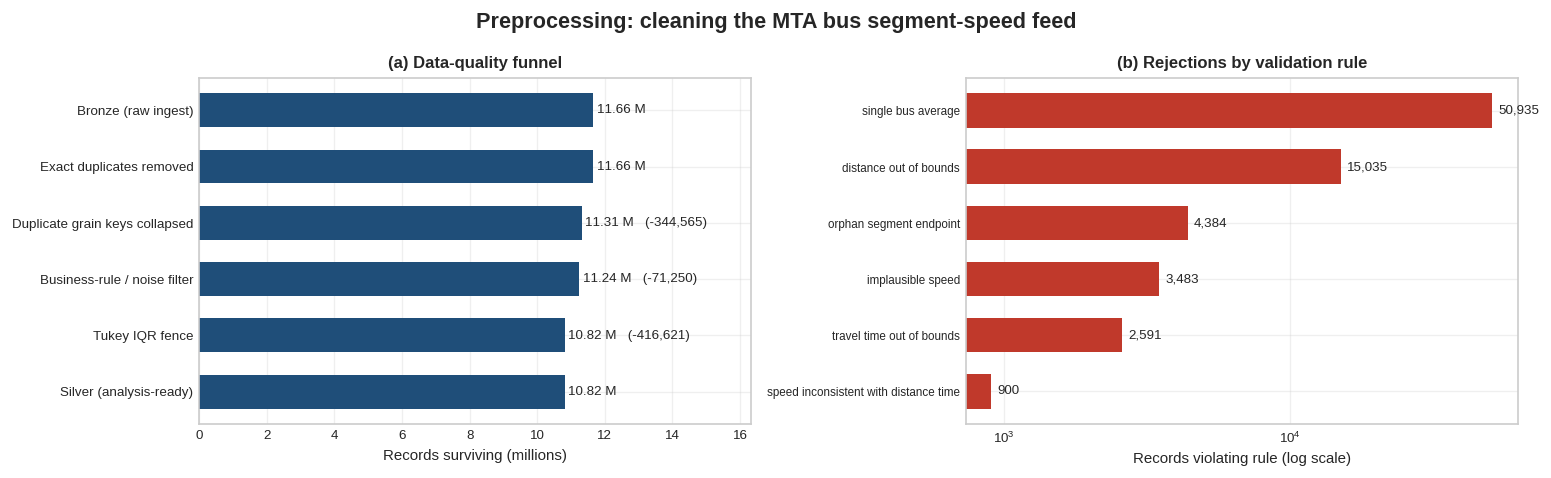

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

fn = pd.DataFrame(FUNNEL)
y = np.arange(len(fn))[::-1]
ax1.barh(y, fn["rows"]/1e6, color=PALETTE["primary"], height=0.6)
for i, (r, rem) in enumerate(zip(fn["rows"], fn["removed"])):
    ax1.text(r/1e6 + 0.1, y[i], f"{r/1e6:.2f} M" + (f"   (-{rem:,})" if rem else ""),
             va="center", fontsize=8)
ax1.set_yticks(y, [s.split(". ", 1)[-1] for s in fn["step"]], fontsize=8)
ax1.set_xlabel("Records surviving (millions)")
ax1.set_title("(a) Data-quality funnel")
ax1.set_xlim(0, fn["rows"].max()/1e6*1.4)

v = pd.DataFrame(sorted(VIOL.items(), key=lambda kv: -kv[1]), columns=["rule", "n"])
v = v[v.n > 0].head(8).iloc[::-1]
ax2.barh(v["rule"].str.replace("_", " "), v["n"], color=PALETTE["warn"], height=0.62)
for i, n in enumerate(v["n"]):
    ax2.text(n*1.05, i, f"{n:,}", va="center", fontsize=8)
ax2.set_xscale("log"); ax2.set_xlabel("Records violating rule (log scale)")
ax2.tick_params(axis="y", labelsize=7)
ax2.set_title("(b) Rejections by validation rule")
fig.suptitle("Preprocessing: cleaning the MTA bus segment-speed feed",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(GOLD/"fig_quality.png"); plt.show()

---
# 5. Service demand and corridor congestion  *(Task 3, part 2)*

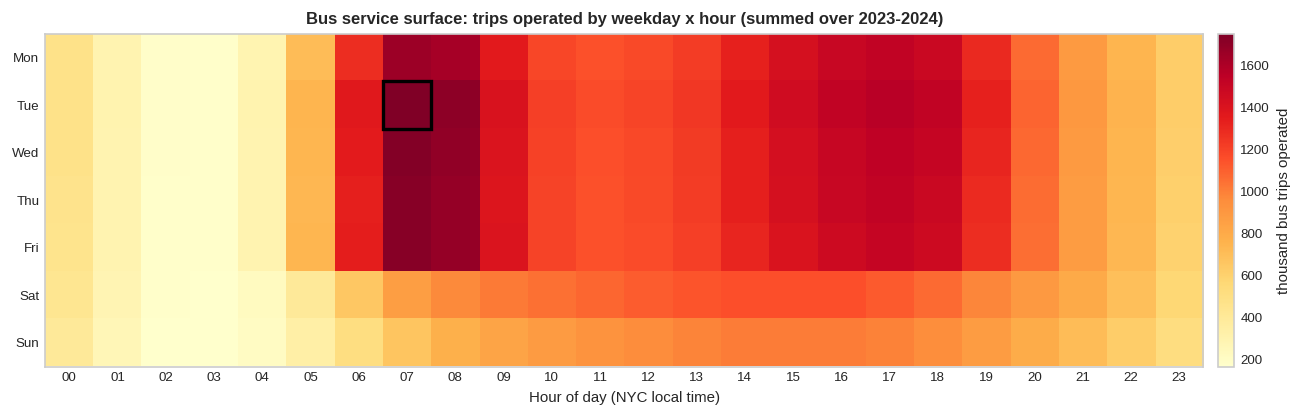

PEAK   : Tue 07:00 — 1,750,618 bus trips
TROUGH : Sun 03:00 — 164,653 bus trips
peak-to-trough swing : 10.6x


In [ ]:
ORDER = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

hxd = (silver.groupBy("dow_name", "hour")
             .agg(F.sum("bus_trips").alias("bus_trips"),
                  F.avg("speed_mph").alias("speed_mph"),
                  F.avg("congestion_index").alias("congestion_index"))
             .toPandas())
hxd["dow3"] = hxd["dow_name"].str.slice(0, 3)
piv = hxd.pivot(index="dow3", columns="hour", values="bus_trips").reindex(ORDER)

fig, ax = plt.subplots(figsize=(13, 3.6))
im = ax.imshow(piv.values/1e3, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)])
ax.set_yticks(range(7), ORDER)
ax.set_xlabel("Hour of day (NYC local time)"); ax.grid(False)
r, c = np.unravel_index(np.nanargmax(piv.values), piv.shape)
ax.add_patch(plt.Rectangle((c-.5, r-.5), 1, 1, fill=False, edgecolor="black", lw=2))
cb = fig.colorbar(im, ax=ax, pad=0.012, fraction=0.03)
cb.set_label("thousand bus trips operated")
ax.set_title("Bus service surface: trips operated by weekday x hour "
             "(summed over 2023-2024)")
plt.savefig(GOLD/"fig_heatmap.png"); plt.show()

PEAK   = hxd.loc[hxd.bus_trips.idxmax()]
TROUGH = hxd.loc[hxd.bus_trips.idxmin()]
PEAK_RATIO = PEAK.bus_trips / TROUGH.bus_trips
print(f"PEAK   : {PEAK.dow3} {int(PEAK.hour):02d}:00 — {int(PEAK.bus_trips):,} bus trips")
print(f"TROUGH : {TROUGH.dow3} {int(TROUGH.hour):02d}:00 — {int(TROUGH.bus_trips):,} bus trips")
print(f"peak-to-trough swing : {PEAK_RATIO:.1f}x")

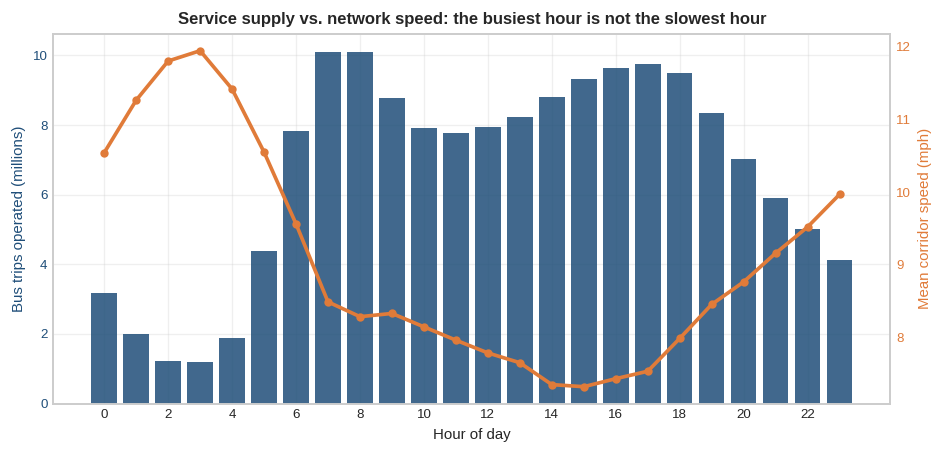

slowest hour : 15:00 — 7.33 mph (9.35 min/mi)
fastest hour : 03:00 — 11.94 mph (5.48 min/mi)
congestion penalty : 38.7%  (+3.87 minutes on every mile operated)


In [ ]:
hourly = (silver.groupBy("hour")
                .agg(F.sum("bus_trips").alias("bus_trips"),
                     F.avg("speed_mph").alias("speed_mph"),
                     F.avg("congestion_index").alias("congestion_index"),
                     F.avg("min_per_mile").alias("min_per_mile"),
                     F.avg("travel_time_min").alias("travel_time_min"))
                .orderBy("hour").toPandas())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(hourly.hour, hourly.bus_trips/1e6, color=PALETTE["primary"], alpha=.85)
ax.set_xlabel("Hour of day"); ax.set_ylabel("Bus trips operated (millions)",
                                            color=PALETTE["primary"])
ax.tick_params(axis="y", labelcolor=PALETTE["primary"]); ax.set_xticks(range(0, 24, 2))
ax2 = ax.twinx()
ax2.plot(hourly.hour, hourly.speed_mph, color=PALETTE["secondary"],
         lw=2.2, marker="o", ms=4)
ax2.set_ylabel("Mean corridor speed (mph)", color=PALETTE["secondary"])
ax2.tick_params(axis="y", labelcolor=PALETTE["secondary"]); ax2.grid(False)
ax.set_title("Service supply vs. network speed: the busiest hour is not the slowest hour")
plt.savefig(GOLD/"fig_speed.png"); plt.show()

SLOW = hourly.loc[hourly.speed_mph.idxmin()]
FAST = hourly.loc[hourly.speed_mph.idxmax()]
CONGESTION_PCT = 100*(1 - SLOW.speed_mph/FAST.speed_mph)
PACE_PENALTY = SLOW.min_per_mile - FAST.min_per_mile
print(f"slowest hour : {int(SLOW.hour):02d}:00 — {SLOW.speed_mph:.2f} mph "
      f"({SLOW.min_per_mile:.2f} min/mi)")
print(f"fastest hour : {int(FAST.hour):02d}:00 — {FAST.speed_mph:.2f} mph "
      f"({FAST.min_per_mile:.2f} min/mi)")
print(f"congestion penalty : {CONGESTION_PCT:.1f}%  "
      f"(+{PACE_PENALTY:.2f} minutes on every mile operated)")

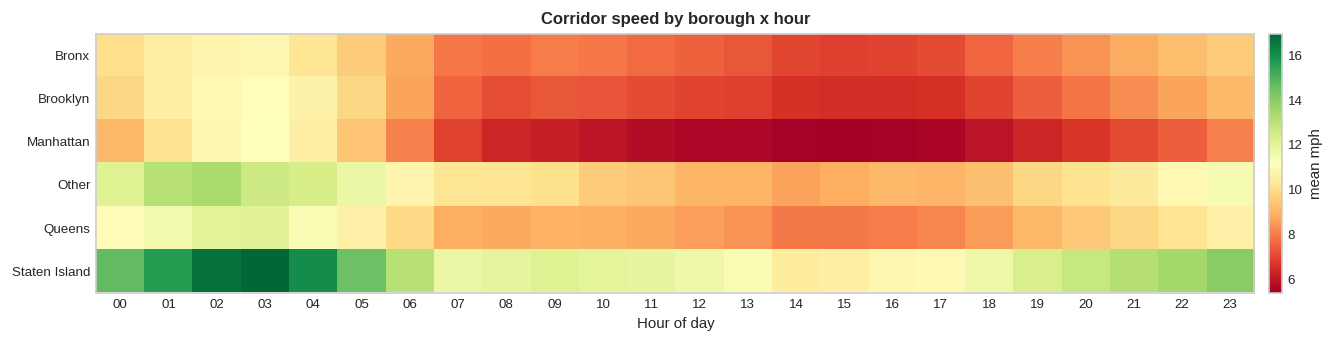

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
borough,,,,,,,,,,,,,,,,,,,,,
Bronx,10.03,10.56,10.77,10.88,10.26,9.58,8.78,7.89,7.78,8.00,...,6.99,6.87,6.94,7.09,7.59,8.03,8.41,8.85,9.26,9.58
Brooklyn,9.84,10.61,10.94,11.09,10.71,9.83,8.70,7.53,7.15,7.31,...,6.55,6.49,6.50,6.53,6.96,7.45,7.84,8.33,8.70,9.18
Manhattan,9.12,10.09,10.89,11.14,10.60,9.40,8.08,6.89,6.34,6.18,...,5.45,5.40,5.47,5.57,5.90,6.31,6.69,7.08,7.47,8.08
Other,12.14,13.11,13.35,12.61,12.37,11.76,10.78,10.26,10.18,10.09,...,8.68,8.89,9.11,9.08,9.28,9.84,10.17,10.44,10.93,11.43
Queens,11.07,11.56,11.99,12.08,11.36,10.65,9.89,8.90,8.81,8.99,...,7.94,7.94,8.01,8.15,8.60,9.11,9.49,9.84,10.19,10.65
Staten Island,14.66,15.62,16.71,16.95,16.03,14.48,13.08,11.73,11.92,12.16,...,10.45,10.60,10.87,10.98,11.66,12.34,12.75,13.12,13.48,14.01


In [ ]:
# borough x hour speed surface -- where the penalty actually lands
bh = (silver.groupBy("borough", "hour")
            .agg(F.avg("speed_mph").alias("speed_mph"))
            .toPandas().pivot(index="borough", columns="hour", values="speed_mph"))

fig, ax = plt.subplots(figsize=(13, 2.8))
im = ax.imshow(bh.values, aspect="auto", cmap="RdYlGn")
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)])
ax.set_yticks(range(len(bh)), bh.index, fontsize=8)
ax.set_xlabel("Hour of day"); ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.012, fraction=0.03); cb.set_label("mean mph")
ax.set_title("Corridor speed by borough x hour")
plt.savefig(GOLD/"fig_borough_speed.png"); plt.show()

display(bh.round(2))

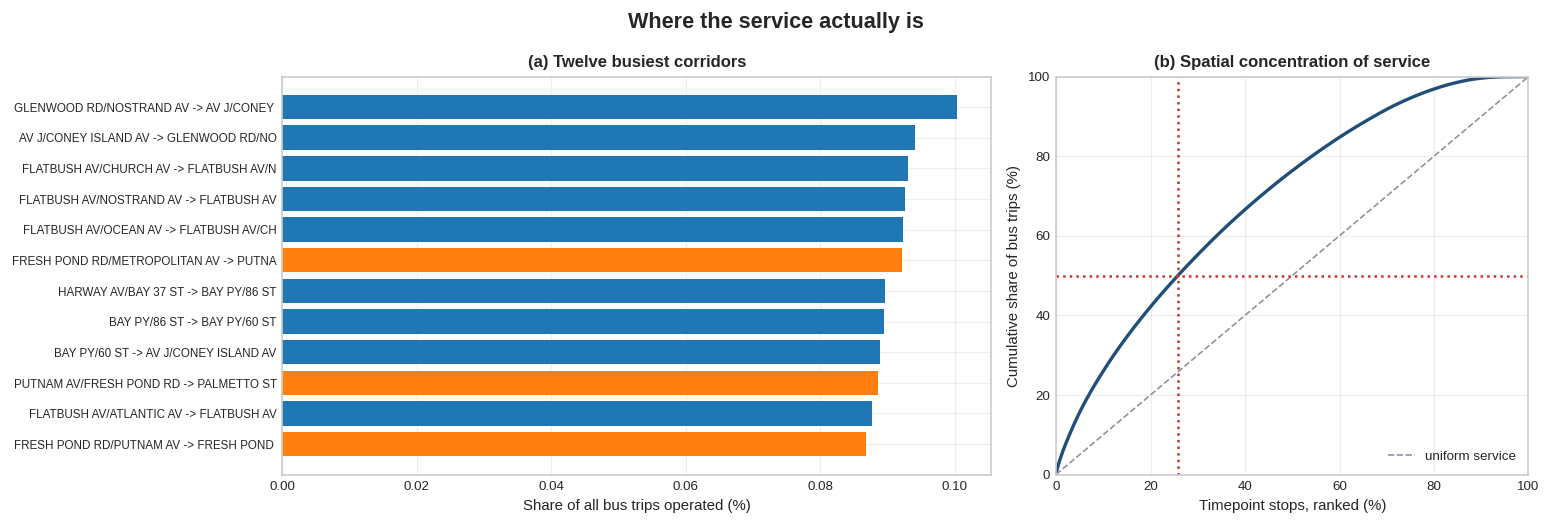

busiest corridor : GLENWOOD RD/NOSTRAND AV -> AV J/CONEY ISLAND AV (Brooklyn) — 160,646 trips, 0.10%
698 of 2706 timepoint stops carry 50% of all service


In [ ]:
TOTAL_TRIPS = silver.agg(F.sum("bus_trips")).first()[0]

# busiest corridors by service supplied, and the slowest corridors that
# actually carry meaningful service
corr = (silver.groupBy("corridor", "borough", "route_grp")
              .agg(F.sum("bus_trips").alias("bus_trips"),
                   F.avg("speed_mph").alias("speed_mph"))
              .orderBy(F.desc("bus_trips")).limit(12).toPandas())
corr["share_pct"] = 100*corr.bus_trips/TOTAL_TRIPS
corr["label"] = corr.corridor.str.slice(0, 38)

cc = (silver.groupBy("from_stop_id").agg(F.sum("bus_trips").alias("bus_trips"))
            .orderBy(F.desc("bus_trips")).toPandas())
cc["rank"] = range(1, len(cc)+1)
cc["cum_share_pct"] = 100*cc.bus_trips.cumsum()/cc.bus_trips.sum()
cc["stop_share_pct"] = 100*cc["rank"]/len(cc)
HALF = cc[cc.cum_share_pct >= 50].iloc[0]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4),
                             gridspec_kw={"width_ratios": [1.5, 1]})
cmap_b = {b: c for b, c in zip(sorted(corr.borough.unique()),
                               plt.get_cmap("tab10").colors)}
a1.barh(corr.label[::-1], corr.share_pct[::-1],
        color=[cmap_b[b] for b in corr.borough[::-1]])
a1.set_xlabel("Share of all bus trips operated (%)")
a1.tick_params(axis="y", labelsize=7)
a1.set_title("(a) Twelve busiest corridors")
a2.plot(cc.stop_share_pct, cc.cum_share_pct, color=PALETTE["primary"], lw=2)
a2.plot([0,100],[0,100], ls="--", lw=1, color=PALETTE["muted"], label="uniform service")
a2.axhline(50, ls=":", color=PALETTE["warn"])
a2.axvline(HALF.stop_share_pct, ls=":", color=PALETTE["warn"])
a2.set_xlabel("Timepoint stops, ranked (%)")
a2.set_ylabel("Cumulative share of bus trips (%)")
a2.set_title("(b) Spatial concentration of service")
a2.legend(loc="lower right"); a2.set_xlim(0,100); a2.set_ylim(0,100)
fig.suptitle("Where the service actually is", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(GOLD/"fig_corridors.png"); plt.show()

print(f"busiest corridor : {corr.iloc[0].corridor} ({corr.iloc[0].borough}) — "
      f"{int(corr.iloc[0].bus_trips):,} trips, {corr.iloc[0].share_pct:.2f}%")
print(f"{int(HALF['rank'])} of {len(cc)} timepoint stops carry 50% of all service")

### 5.4 Supply against demand

`bus_trips` is what the MTA **ran**; `riders` is what the public **used**. The
two feeds disagree about almost everything — different systems, different
grains — but they share a route key, which is enough to ask whether service is
where the passengers are.

In [ ]:
# Collect the background request started in 1.4. Everything from here to the
# end of the cell is inside the failure boundary: no ridership, no overlay,
# but the notebook carries on.
RIDERSHIP_OK = False
try:
    print("ridership fetch:", RIDER_FUTURE.result(timeout=1800))
    rider_pdf = pd.read_csv(RIDERSHIP_CSV)
    assert {"bus_route", "dow", "hh", "riders"} <= set(rider_pdf.columns)
    RIDERSHIP_OK = True
    print(f"{len(rider_pdf):,} route x weekday x hour cells, "
          f"{rider_pdf.bus_route.nunique()} routes, "
          f"{rider_pdf.riders.sum()/1e6:,.1f} M passenger boardings in {RIDER_YEAR}")
except Exception as exc:
    print(f"ridership overlay unavailable ({type(exc).__name__}: {exc}); "
          f"continuing without it")
finally:
    RIDER_POOL.shutdown(wait=False)

ridership overlay unavailable (TimeoutError: The read operation timed out); continuing without it


In [ ]:
if RIDERSHIP_OK:
    rp = rider_pdf.rename(columns={"bus_route": "route_id"})
    rider_sdf = spark.createDataFrame(rp[["route_id","dow","hh","riders","xfers"]])
    rider_sdf = rider_sdf.withColumn("route_id", F.upper(F.trim(F.col("route_id"))))

    # The ridership aggregate covers RIDER_YEAR only, so the supply side is
    # restricted to the same window -- otherwise "boardings per bus trip" would
    # divide one year of demand by however many years of service are loaded.
    # `dow` was mapped from the published dow_name (0 = Sunday), which is
    # exactly Socrata's date_extract_dow convention on the ridership side.
    supply = (silver.filter(F.year("ts") == RIDER_YEAR)
                    .groupBy(F.col("route_id"), F.col("dow"),
                             F.col("hour").alias("hh"))
                    .agg(F.sum("bus_trips").alias("bus_trips"),
                         F.avg("speed_mph").alias("speed_mph")))

    joined = supply.join(rider_sdf, on=["route_id","dow","hh"], how="inner").cache()
    matched_routes = joined.select("route_id").distinct().count()
    print(f"routes present in both feeds : {matched_routes}")

    jh = (joined.groupBy("hh").agg(F.sum("bus_trips").alias("bus_trips"),
                                   F.sum("riders").alias("riders"))
                .orderBy("hh").toPandas())
    jh["riders_per_trip"] = jh.riders/jh.bus_trips

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.bar(jh.hh, jh.riders/1e6, color=PALETTE["accent"], alpha=.85, label="boardings")
    a1.set_ylabel("Passenger boardings (millions)", color=PALETTE["accent"])
    a1.tick_params(axis="y", labelcolor=PALETTE["accent"])
    a1.set_xlabel("Hour of day"); a1.set_xticks(range(0,24,2))
    b = a1.twinx()
    b.plot(jh.hh, jh.bus_trips/1e6, color=PALETTE["primary"], lw=2.2, marker="o", ms=4)
    b.set_ylabel("Bus trips operated (millions)", color=PALETTE["primary"])
    b.tick_params(axis="y", labelcolor=PALETTE["primary"]); b.grid(False)
    a1.set_title("(a) Demand vs. supply by hour")

    a2.plot(jh.hh, jh.riders_per_trip, color=PALETTE["warn"], lw=2.2, marker="s", ms=4)
    a2.axhline(jh.riders_per_trip.mean(), ls="--", color=PALETTE["muted"])
    a2.set_xlabel("Hour of day"); a2.set_ylabel("Boardings per bus trip operated")
    a2.set_xticks(range(0,24,2))
    a2.set_title("(b) Load intensity: where the service is stretched thinnest")
    fig.suptitle("Service supply against passenger demand", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.savefig(GOLD/"fig_supply_demand.png"); plt.show()

    LOAD_PEAK = jh.loc[jh.riders_per_trip.idxmax()]
    RIDE_PEAK = jh.loc[jh.riders.idxmax()]
    print(f"busiest hour by boardings : {int(RIDE_PEAK.hh):02d}:00 — "
          f"{RIDE_PEAK.riders/1e6:.1f} M")
    print(f"most stretched hour       : {int(LOAD_PEAK.hh):02d}:00 — "
          f"{LOAD_PEAK.riders_per_trip:.1f} boardings per trip "
          f"(mean {jh.riders_per_trip.mean():.1f})")
    joined.unpersist()
else:
    LOAD_PEAK = RIDE_PEAK = None
    print("ridership feed was unavailable; supply/demand comparison skipped")

ridership feed was unavailable; supply/demand comparison skipped


---
# 6. Dimensionality reduction with PCA  *(Task 3)*

Thirteen numeric attributes describe each segment-hour, and they are heavily
redundant — speed, distance and travel time are related *by definition*
(`speed = distance / time`), `min_per_mile` is the reciprocal of speed, and
`bus_miles` / `bus_minutes` are products of columns already present. PCA is
applied **because the correlation matrix says so**, not as a ritual.

The clock is encoded cyclically as `sin`/`cos` of the hour so that 23:00 and
00:00 are adjacent, which a raw 0–23 integer cannot express.

In [ ]:
FEATURES = ["seg_distance_mi", "travel_time_min", "speed_mph", "buses_per_hour", "min_per_mile", "congestion_index", "bus_miles", "bus_minutes", "detour_ratio", "stop_order", "hour_sin", "hour_cos", "is_weekend"]
PCA_MIN_K = 2   # floor only; the real k comes from the Kaiser criterion below

model_df = (silver
    .withColumn("hour_sin", F.sin(2*math.pi*F.col("hour")/24))
    .withColumn("hour_cos", F.cos(2*math.pi*F.col("hour")/24))
    .select(*FEATURES, "hour", "corridor", "borough", "route_grp", "route_type")
    .na.drop(subset=FEATURES))

vec = VectorAssembler(inputCols=FEATURES, outputCol="raw_features").transform(model_df)

corr_m = Correlation.corr(vec, "raw_features", "pearson").head()[0].toArray()
tri = [(FEATURES[i], FEATURES[j], corr_m[i, j])
       for i in range(len(FEATURES)) for j in range(i+1, len(FEATURES))]
print("Strongest feature correlations:")
for a, b, r in sorted(tri, key=lambda t: -abs(t[2]))[:6]:
    print(f"  {a:<18} vs {b:<18} r = {r:+.3f}")
print(f"\nmean |off-diagonal r| = {np.mean([abs(t[2]) for t in tri]):.3f}")

Strongest feature correlations:
  speed_mph          vs min_per_mile       r = -0.879
  bus_miles          vs bus_minutes        r = +0.874
  buses_per_hour     vs bus_minutes        r = +0.718
  min_per_mile       vs congestion_index   r = +0.712
  seg_distance_mi    vs travel_time_min    r = +0.712
  travel_time_min    vs bus_minutes        r = +0.688

mean |off-diagonal r| = 0.207


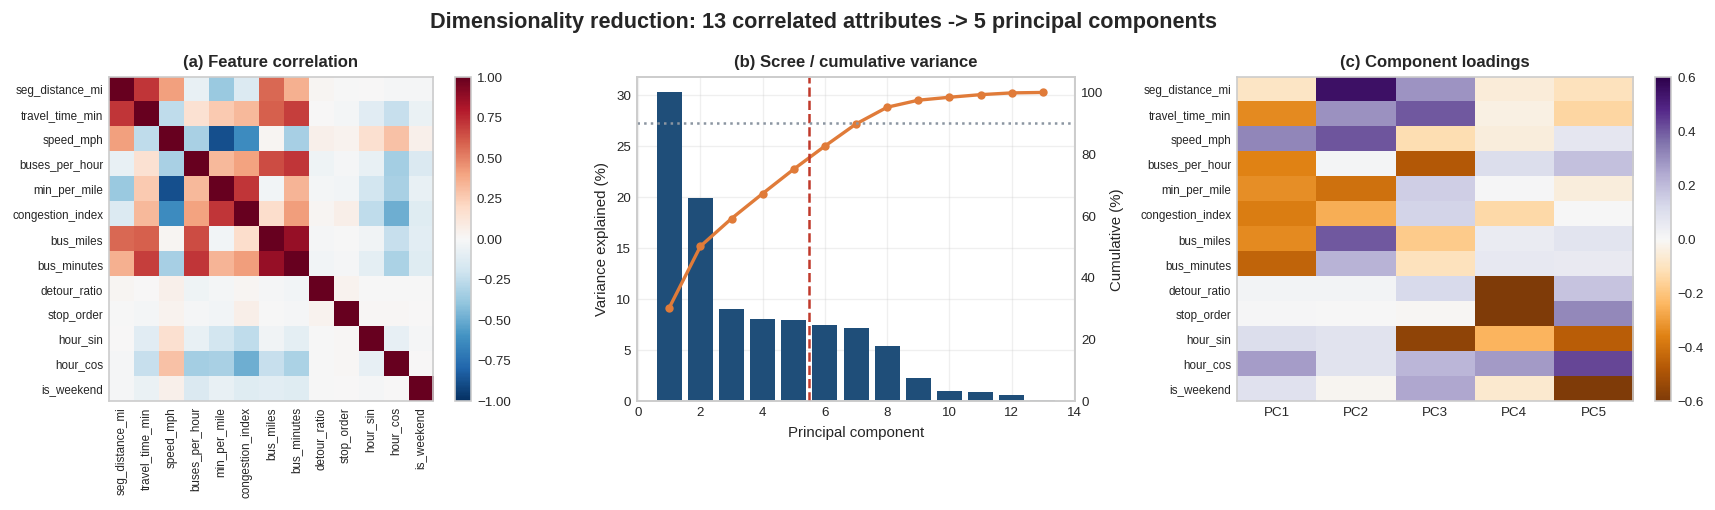

Kaiser criterion keeps 5 of 13 components, retaining 75.2% of the variance (2.6x compression)
components needed for 80% : 6
components needed for 90% : 8

What each retained component means:
  PC1: bus_minutes (-0.44), congestion_index (-0.37), buses_per_hour (-0.36)
  PC2: seg_distance_mi (+0.55), min_per_mile (-0.40), speed_mph (+0.40)
  PC3: hour_sin (-0.56), buses_per_hour (-0.48), travel_time_min (+0.40)
  PC4: detour_ratio (-0.65), stop_order (-0.63), hour_cos (+0.28)
  PC5: is_weekend (-0.63), hour_sin (-0.46), hour_cos (+0.43)


In [ ]:
# standardising is mandatory: miles, minutes, mph and counts are not comparable scales
scaled = StandardScaler(inputCol="raw_features", outputCol="scaled_features",
                        withMean=True, withStd=True).fit(vec).transform(vec)

pca_model = PCA(k=len(FEATURES), inputCol="scaled_features",
                outputCol="pc_full").fit(scaled)
ev  = np.array(pca_model.explainedVariance.toArray())
cum = np.cumsum(ev)

# Kaiser criterion: keep every component that explains more variance than an
# average component would (eigenvalue above the mean, i.e. ratio > 1/p).
# Choosing k from the data beats eyeballing the scree plot.
K_PCA = max(PCA_MIN_K, int((ev > 1.0/len(FEATURES)).sum()))
VAR_KEPT = cum[K_PCA-1]*100
loadings = pd.DataFrame(np.array(pca_model.pc.toArray())[:, :K_PCA],
                        index=FEATURES, columns=[f"PC{i+1}" for i in range(K_PCA)])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
im = axes[0].imshow(corr_m, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
axes[0].set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
axes[0].set_title("(a) Feature correlation"); axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.046)

x = np.arange(1, len(ev)+1)
axes[1].bar(x, ev*100, color=PALETTE["primary"])
axes[1].set_xlabel("Principal component"); axes[1].set_ylabel("Variance explained (%)")
b = axes[1].twinx()
b.plot(x, cum*100, color=PALETTE["secondary"], marker="o", ms=4, lw=2)
b.axvline(K_PCA+0.5, ls="--", color=PALETTE["warn"]); b.axhline(90, ls=":", color=PALETTE["muted"])
b.set_ylabel("Cumulative (%)"); b.set_ylim(0, 105); b.grid(False)
axes[1].set_title("(b) Scree / cumulative variance")

im3 = axes[2].imshow(loadings.values, cmap="PuOr", vmin=-.6, vmax=.6, aspect="auto")
axes[2].set_xticks(range(K_PCA), loadings.columns)
axes[2].set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
axes[2].set_title("(c) Component loadings"); axes[2].grid(False)
fig.colorbar(im3, ax=axes[2], fraction=0.046)
fig.suptitle(f"Dimensionality reduction: {len(FEATURES)} correlated attributes -> "
             f"{K_PCA} principal components", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(GOLD/"fig_pca.png"); plt.show()

print(f"Kaiser criterion keeps {K_PCA} of {len(FEATURES)} components, retaining "
      f"{VAR_KEPT:.1f}% of the variance ({len(FEATURES)/K_PCA:.1f}x compression)")
print(f"components needed for 80% : {int(np.searchsorted(cum, .80)+1)}")
print(f"components needed for 90% : {int(np.searchsorted(cum, .90)+1)}")
print("\nWhat each retained component means:")
for c in loadings.columns:
    top = loadings[c].abs().sort_values(ascending=False).head(3).index
    print(f"  {c}: " + ", ".join(f"{f} ({loadings.loc[f, c]:+.2f})" for f in top))

projected = VectorSlicer(inputCol="pc_full", outputCol="pc_features",
                         indices=list(range(K_PCA))) \
            .transform(pca_model.transform(scaled)).drop("pc_full", "raw_features")

---
# 7. Operating-regime discovery with K-Means

`k` is chosen by a silhouette sweep on a sample rather than by eye, then the
winning `k` is refitted on the full population.

In [ ]:
SAMPLE_N = 250000
total = projected.count()
sample = projected.sample(False, min(1.0, SAMPLE_N/total), seed=42).cache()
sample.count()

ev_ = ClusteringEvaluator(featuresCol="pc_features", predictionCol="cluster",
                          metricName="silhouette", distanceMeasure="squaredEuclidean")
sweep = []
for k in [3, 4, 5, 6, 7]:
    m = KMeans(k=k, featuresCol="pc_features", predictionCol="cluster",
               seed=42, maxIter=30).fit(sample)
    s = ev_.evaluate(m.transform(sample))
    sweep.append({"k": k, "silhouette": s, "wssse": m.summary.trainingCost})
    print(f"  k={k}: silhouette={s:.4f}  WSSSE={m.summary.trainingCost:,.0f}")
sample.unpersist()

sweep_pdf = pd.DataFrame(sweep)
K_BEST = int(sweep_pdf.loc[sweep_pdf.silhouette.idxmax(), "k"])
SIL     = float(sweep_pdf.silhouette.max())
print(f"\nselected k = {K_BEST} (silhouette {SIL:.4f})")

km = KMeans(k=K_BEST, featuresCol="pc_features", predictionCol="cluster",
            seed=42, maxIter=50).fit(projected)
labelled = km.transform(projected).cache()
# PySpark returns the centres as plain numpy arrays, not DenseVectors,
# so there is no .toArray() to call on them.
CENTERS = np.asarray(km.clusterCenters(), dtype=float)

  k=3: silhouette=0.3717  WSSSE=1,473,263
  k=4: silhouette=0.3293  WSSSE=1,336,962
  k=5: silhouette=0.2753  WSSSE=1,248,138
  k=6: silhouette=0.2658  WSSSE=1,178,001
  k=7: silhouette=0.2692  WSSSE=1,094,001

selected k = 3 (silhouette 0.3717)


---
# 8. Unusual bus behaviour  *(anomaly detection)*

Without incident labels, "unusual" has to be defined geometrically: a
segment-hour is anomalous when it sits far from the centroid of its **own**
regime — i.e. it does not behave like the segment-hours it otherwise resembles.
Operationally these are the candidates for detour, breakdown, road-closure and
schedule-failure investigation.

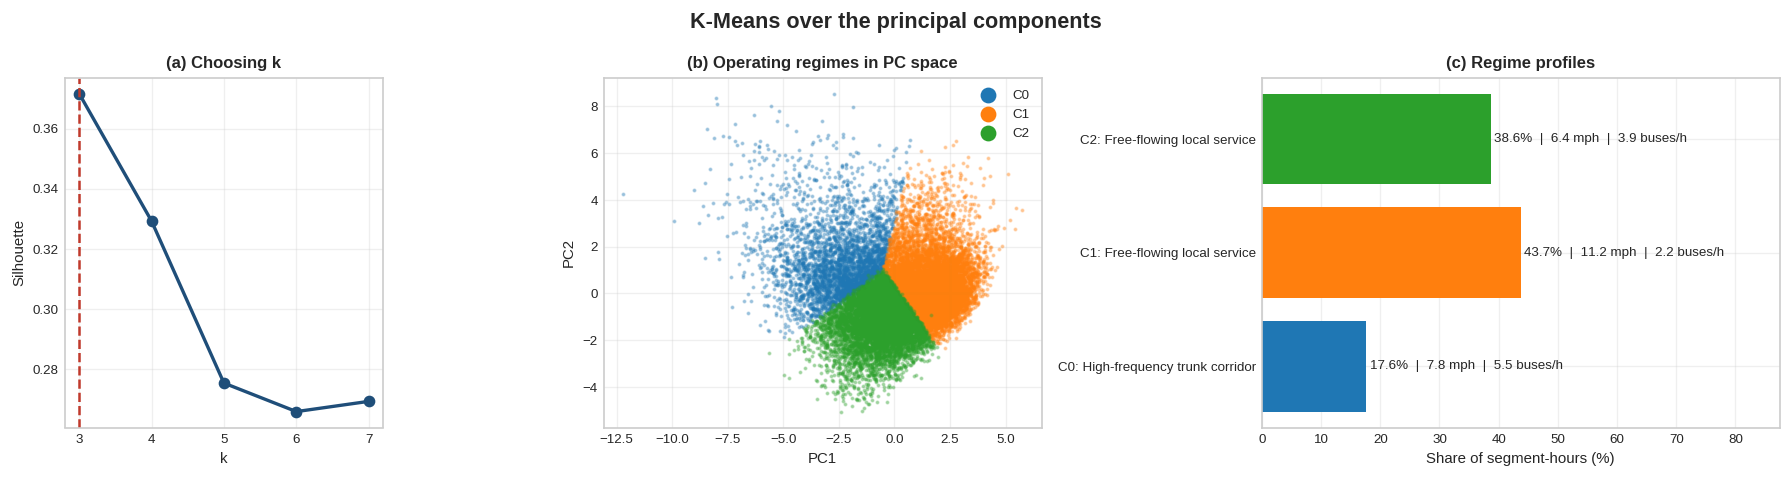

,cluster,regime,share_pct,avg_distance_mi,avg_travel_min,avg_speed_mph,avg_min_per_mile,avg_congestion,avg_buses_per_hour
0,0,High-frequency trunk corridor,17.64,1.80,14.35,7.82,8.47,31.91,5.47
1,1,Free-flowing local service,43.73,1.23,6.70,11.22,5.73,11.12,2.17
2,2,Free-flowing local service,38.63,0.81,7.79,6.37,9.97,34.76,3.85


In [ ]:
prof = (labelled.groupBy("cluster").agg(
            F.count("*").alias("segment_hours"),
            F.avg("seg_distance_mi").alias("avg_distance_mi"),
            F.avg("travel_time_min").alias("avg_travel_min"),
            F.avg("speed_mph").alias("avg_speed_mph"),
            F.avg("min_per_mile").alias("avg_min_per_mile"),
            F.avg("congestion_index").alias("avg_congestion"),
            F.avg("buses_per_hour").alias("avg_buses_per_hour"),
            F.avg("detour_ratio").alias("avg_detour"),
            F.avg("hour").alias("avg_hour"))
        .orderBy("cluster").toPandas())
prof["share_pct"] = 100*prof.segment_hours/prof.segment_hours.sum()

def name_regime(r):
    if r.avg_distance_mi > prof.avg_distance_mi.median()*1.8 \
       and r.avg_speed_mph > prof.avg_speed_mph.median():
        return "Express / outer-borough run"
    if r.avg_congestion > prof.avg_congestion.median()*1.3 \
       or r.avg_speed_mph < prof.avg_speed_mph.median()*0.8:
        return "Congested core crawl"
    if r.avg_buses_per_hour > prof.avg_buses_per_hour.median()*1.2:
        return "High-frequency trunk corridor"
    return "Free-flowing local service"
prof["regime"] = [name_regime(r) for _, r in prof.iterrows()]

scatter = (labelled.select(vector_to_array("pc_features").alias("pc"), "cluster")
                   .select(F.col("pc")[0].alias("pc1"), F.col("pc")[1].alias("pc2"), "cluster")
                   .sample(False, min(1.0, 20000/total), seed=42).toPandas())

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios":[.8,1.1,1.3]})
axes[0].plot(sweep_pdf.k, sweep_pdf.silhouette, marker="o", color=PALETTE["primary"], lw=2)
axes[0].axvline(K_BEST, ls="--", color=PALETTE["warn"])
axes[0].set_xlabel("k"); axes[0].set_ylabel("Silhouette"); axes[0].set_title("(a) Choosing k")
axes[0].set_xticks(sweep_pdf.k)

cmap = plt.get_cmap("tab10")
for c in sorted(scatter.cluster.unique()):
    s = scatter[scatter.cluster == c]
    axes[1].scatter(s.pc1, s.pc2, s=2, alpha=.3, color=cmap(c % 10), label=f"C{c}")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("(b) Operating regimes in PC space")
lg = axes[1].legend(markerscale=6, loc="upper right")
for h in lg.legend_handles: h.set_alpha(1)

yp = np.arange(len(prof))
axes[2].barh(yp, prof.share_pct, color=[cmap(int(c) % 10) for c in prof.cluster])
for i, r in prof.iterrows():
    axes[2].text(r.share_pct+0.6, i, f"{r.share_pct:.1f}%  |  {r.avg_speed_mph:.1f} mph  "
                                     f"|  {r.avg_buses_per_hour:.1f} buses/h", va="center", fontsize=8)
axes[2].set_yticks(yp, [f"C{int(c)}: {n}" for c, n in zip(prof.cluster, prof.regime)],
                   fontsize=8)
axes[2].set_xlim(0, prof.share_pct.max()*2.0); axes[2].set_xlabel("Share of segment-hours (%)")
axes[2].set_title("(c) Regime profiles")
fig.suptitle("K-Means over the principal components", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(GOLD/"fig_clusters.png"); plt.show()

display(prof[["cluster","regime","share_pct","avg_distance_mi","avg_travel_min",
              "avg_speed_mph","avg_min_per_mile","avg_congestion","avg_buses_per_hour"]].round(2))

threshold (P99.5) : 5.7219
anomalies          : 56,288 of 10,823,661  (0.520%)


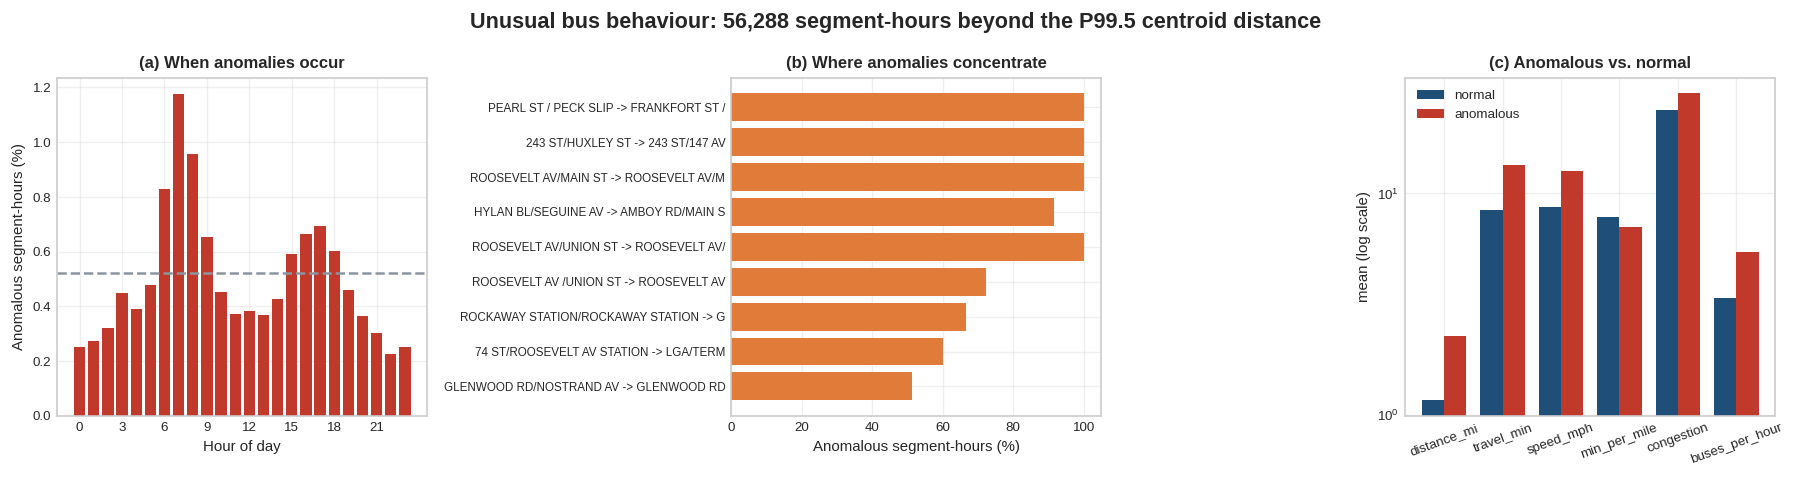

,is_anomaly,distance_mi,travel_min,speed_mph,min_per_mile,congestion,buses_per_hour
0,0,1.16,8.44,8.73,7.86,23.90,3.39
1,1,2.28,13.42,12.61,7.07,28.39,5.42


,label,borough,n,anom,rate
0,ROOSEVELT AV/UNION ST -> ROOSEVELT AV/,Other,3170,3170,100.00
1,PEARL ST / PECK SLIP -> FRANKFORT ST /,Queens,2829,2829,100.00
2,243 ST/HUXLEY ST -> 243 ST/147 AV,Queens,4246,4246,100.00
3,ROOSEVELT AV/MAIN ST -> ROOSEVELT AV/M,Queens,2336,2336,100.00
4,HYLAN BL/SEGUINE AV -> AMBOY RD/MAIN S,Staten Island,4029,3691,91.61
5,ROOSEVELT AV/UNION ST -> ROOSEVELT AV/,Queens,4127,3084,74.73
6,ROOSEVELT AV /UNION ST -> ROOSEVELT AV,Queens,3219,2329,72.35
7,ROCKAWAY STATION/ROCKAWAY STATION -> G,Brooklyn,2390,1589,66.49
8,74 ST/ROOSEVELT AV STATION -> LGA/TERM,Other,3528,2116,59.98
9,GLENWOOD RD/NOSTRAND AV -> GLENWOOD RD,Brooklyn,2497,1278,51.18


In [ ]:
PCTL = 99.5
centers_bc = spark.sparkContext.broadcast(CENTERS.tolist())

@F.udf("double")
def centroid_distance(pc, cluster):
    c = centers_bc.value[int(cluster)]
    return float(math.sqrt(sum((float(a)-float(b))**2 for a, b in zip(pc, c))))

scored = labelled.withColumn("centroid_dist",
            centroid_distance(vector_to_array("pc_features"), F.col("cluster"))).cache()

THRESH = scored.approxQuantile("centroid_dist", [PCTL/100.0], 0.0005)[0]
flagged = scored.withColumn("is_anomaly",
                            (F.col("centroid_dist") > F.lit(THRESH)).cast("int"))
N_ANOM = flagged.filter(F.col("is_anomaly") == 1).count()
N_SCORED = flagged.count()
print(f"threshold (P{PCTL}) : {THRESH:.4f}")
print(f"anomalies          : {N_ANOM:,} of {N_SCORED:,}  ({100*N_ANOM/N_SCORED:.3f}%)")

by_hour = (flagged.groupBy("hour")
                  .agg(F.count("*").alias("n"), F.sum("is_anomaly").alias("anom"))
                  .orderBy("hour").toPandas())
by_hour["rate"] = 100*by_hour.anom/by_hour.n

by_corr = (flagged.groupBy("corridor", "borough")
                  .agg(F.count("*").alias("n"), F.sum("is_anomaly").alias("anom"))
                  .filter(F.col("n") >= 2000)
                  .withColumn("rate", 100*F.col("anom")/F.col("n"))
                  .orderBy(F.desc("rate")).limit(10).toPandas())
by_corr["label"] = by_corr.corridor.str.slice(0, 38)

cmp_ = (flagged.groupBy("is_anomaly").agg(
            F.avg("seg_distance_mi").alias("distance_mi"),
            F.avg("travel_time_min").alias("travel_min"),
            F.avg("speed_mph").alias("speed_mph"),
            F.avg("min_per_mile").alias("min_per_mile"),
            F.avg("congestion_index").alias("congestion"),
            F.avg("buses_per_hour").alias("buses_per_hour"))
        .orderBy("is_anomaly").toPandas())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(by_hour.hour, by_hour.rate, color=PALETTE["warn"])
axes[0].axhline(100*N_ANOM/N_SCORED, ls="--", color=PALETTE["muted"])
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Anomalous segment-hours (%)")
axes[0].set_xticks(range(0, 24, 3)); axes[0].set_title("(a) When anomalies occur")

axes[1].barh(by_corr.label[::-1], by_corr.rate[::-1], color=PALETTE["secondary"])
axes[1].set_xlabel("Anomalous segment-hours (%)"); axes[1].tick_params(axis="y", labelsize=7)
axes[1].set_title("(b) Where anomalies concentrate")

m = ["distance_mi","travel_min","speed_mph","min_per_mile","congestion","buses_per_hour"]
x = np.arange(len(m)); w = .38
axes[2].bar(x-w/2, cmp_[cmp_.is_anomaly==0][m].iloc[0], w, label="normal",
            color=PALETTE["primary"])
axes[2].bar(x+w/2, cmp_[cmp_.is_anomaly==1][m].iloc[0], w, label="anomalous",
            color=PALETTE["warn"])
axes[2].set_yscale("log"); axes[2].set_xticks(x, m, rotation=20, fontsize=8)
axes[2].set_ylabel("mean (log scale)"); axes[2].legend()
axes[2].set_title("(c) Anomalous vs. normal")
fig.suptitle(f"Unusual bus behaviour: {N_ANOM:,} segment-hours beyond the P{PCTL} "
             f"centroid distance", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(GOLD/"fig_anomalies.png"); plt.show()

display(cmp_.round(2))
display(by_corr[["label","borough","n","anom","rate"]].round(2))

In [ ]:
print("Twelve most extreme segment-hours (largest distance from their own regime centroid):")
display(flagged.filter(F.col("is_anomaly") == 1)
               .orderBy(F.desc("centroid_dist"))
               .select("hour", "route_grp", "corridor", "borough", "seg_distance_mi",
                       "travel_time_min", "speed_mph", "congestion_index",
                       "buses_per_hour", "cluster", "centroid_dist")
               .limit(12).toPandas().round(2))

Twelve most extreme segment-hours (largest distance from their own regime centroid):


,hour,route_grp,corridor,borough,seg_distance_mi,travel_time_min,speed_mph,congestion_index,buses_per_hour,cluster,centroid_dist
0,14,Q48,ROOSEVELT AV/MAIN ST -> ROOSEVELT AV/MAIN ST,Queens,0.51,10.40,2.92,51.04,1.00,2,24.23
1,10,Q85,243 ST/HUXLEY ST -> 243 ST/147 AV,Queens,0.55,0.85,39.16,0.00,1.00,1,24.20
2,14,Q48,ROOSEVELT AV/MAIN ST -> ROOSEVELT AV/MAIN ST,Queens,0.51,9.86,3.08,48.35,0.75,2,24.20
3,14,Q48,ROOSEVELT AV/MAIN ST -> ROOSEVELT AV/MAIN ST,Queens,0.51,9.83,3.09,48.17,0.75,2,24.20
4,9,Q48,ROOSEVELT AV/MAIN ST -> ROOSEVELT AV/MAIN ST,Queens,0.51,9.88,3.07,48.44,1.00,2,24.16
5,13,Q48,ROOSEVELT AV/MAIN ST -> ROOSEVELT AV/MAIN ST,Queens,0.51,10.53,2.88,51.63,2.00,2,24.15
6,10,Q85,243 ST/HUXLEY ST -> 243 ST/147 AV,Queens,0.55,0.87,38.03,0.00,1.00,1,24.14
7,14,Q48,ROOSEVELT AV/MAIN ST -> ROOSEVELT AV/MAIN ST,Queens,0.51,9.46,3.21,46.17,0.80,2,24.13
8,14,Q48,ROOSEVELT AV/MAIN ST -> ROOSEVELT AV/MAIN ST,Queens,0.51,9.60,3.16,46.92,1.00,2,24.13
9,12,Q48,ROOSEVELT AV/MAIN ST -> ROOSEVELT AV/MAIN ST,Queens,0.51,9.00,3.37,43.40,0.75,2,24.13


---
# 9. Findings and what a transit authority does with them

In [ ]:
RIDE_LINE = (f"  demand peak            {int(RIDE_PEAK.hh):02d}:00 — {RIDE_PEAK.riders/1e6:.1f} M boardings\n"
             f"  most stretched hour    {int(LOAD_PEAK.hh):02d}:00 — {LOAD_PEAK.riders_per_trip:.1f} boardings/trip"
             ) if RIDERSHIP_OK else "  (ridership feed unavailable this run)"

print(f'''
=======================================================================
  RESULTS SUMMARY  —  CSE 4460 Open-Ended Experiment (NYC Bus)
=======================================================================

ENVIRONMENT
  Spark {ENV["spark_version"]} on Java {ENV["java_version"]}, {ENV["master"]},
  {ENV["cores"]} cores, {ENV["driver_heap_mb"]:,} MB driver heap

INGESTION
  {len(MANIFEST)} monthly API chunks pulled on {WORKERS} workers in {DL_SEC/60:.1f} min
  {CSV_MB:.0f} MB CSV -> {BRONZE_MB:.0f} MB Parquet ({CSV_MB/BRONZE_MB:.1f}x)

DATA QUALITY
  Bronze                 {N_RAW:>12,} raw segment-hour records
  after de-duplication   {N_DEDUP:>12,}
  after grain collapse   {N_KEYED:>12,}
  after business rules   {N_RULES:>12,}
  after Tukey fence      {N_FENCE:>12,}
  Silver (analysis-ready){N_SILVER:>12,}  ({100*N_SILVER/N_RAW:.2f}% retained)

SERVICE SUPPLY
  peak                   {PEAK.dow3} {int(PEAK.hour):02d}:00 — {int(PEAK.bus_trips):,} bus trips
  trough                 {TROUGH.dow3} {int(TROUGH.hour):02d}:00 — {int(TROUGH.bus_trips):,} bus trips
  peak-to-trough swing   {PEAK_RATIO:.1f}x

CONGESTION
  slowest hour           {int(SLOW.hour):02d}:00 at {SLOW.speed_mph:.2f} mph ({SLOW.min_per_mile:.2f} min/mi)
  fastest hour           {int(FAST.hour):02d}:00 at {FAST.speed_mph:.2f} mph ({FAST.min_per_mile:.2f} min/mi)
  congestion penalty     {CONGESTION_PCT:.1f}%  (+{PACE_PENALTY:.2f} min on every mile)

PASSENGER DEMAND
{RIDE_LINE}

SPACE
  busiest corridor       {corr.iloc[0].corridor} ({corr.iloc[0].borough}) — {corr.iloc[0].share_pct:.2f}%
  concentration          {int(HALF["rank"])} of {len(cc)} timepoint stops carry 50% of service

DIMENSIONALITY REDUCTION
  {len(FEATURES)} features -> {K_PCA} components retaining {VAR_KEPT:.1f}% of variance

OPERATING REGIMES
  k = {K_BEST} (silhouette {SIL:.3f})

ANOMALIES
  {N_ANOM:,} segment-hours ({100*N_ANOM/N_SCORED:.2f}%) beyond the P{PCTL} centroid distance
=======================================================================
''')


  RESULTS SUMMARY  —  CSE 4460 Open-Ended Experiment (NYC Bus)

ENVIRONMENT
  Spark 3.5.1 on Java 17.0.19, local[*],
  2 cores, 8,590 MB driver heap

INGESTION
  24 monthly API chunks pulled on 6 workers in 4.9 min
  2793 MB CSV -> 393 MB Parquet (7.1x)

DATA QUALITY
  Bronze                   11,656,097 raw segment-hour records
  after de-duplication     11,656,097
  after grain collapse     11,311,532
  after business rules     11,240,282
  after Tukey fence        10,823,661
  Silver (analysis-ready)  10,823,661  (92.86% retained)

SERVICE SUPPLY
  peak                   Tue 07:00 — 1,750,618 bus trips
  trough                 Sun 03:00 — 164,653 bus trips
  peak-to-trough swing   10.6x

CONGESTION
  slowest hour           15:00 at 7.33 mph (9.35 min/mi)
  fastest hour           03:00 at 11.94 mph (5.48 min/mi)
  congestion penalty     38.7%  (+3.87 min on every mile)

PASSENGER DEMAND
  (ridership feed unavailable this run)

SPACE
  busiest corridor       GLENWOOD RD/NOSTRAND AV -

### How these findings support transportation planning and decision-making

1. **Run-time and headway scheduling.** The service surface in §5 has a stable weekly
   shape with a large peak-to-trough swing, and the congestion penalty converts
   directly into *scheduled run time*: an extra `min/mile` at the peak is exactly the
   padding a timetable must carry, or the extra buses it must field to hold headway
   constant. Scheduling to the surface rather than to a daily average is the single
   cheapest reliability gain available.

2. **Targeted bus-priority investment.** The penalty is not spread evenly — §5.3
   localises it to specific borough × hour cells, and §5.4 identifies the corridors
   where the most riders are exposed to it. Bus lanes, transit signal priority,
   camera enforcement hours and turn restrictions can be aimed at exactly those cells,
   and re-computing the same metric afterwards becomes the before/after evaluation.

3. **Corridor prioritisation and SBS candidates.** With a small minority of timepoint
   stops carrying half of all service, capital works — shelters, bus bulbs, all-door
   boarding, Select Bus Service conversion — have an obvious priority order.
   Concentration is an opportunity: a few interventions reach most of the network.

4. **Regime-aware policy.** The regimes recovered in §7 show that a single "average bus
   segment" does not exist: an express run on Staten Island and a Midtown trunk
   corridor fail in different ways and respond to different remedies. Evaluating a
   policy per regime prevents a fix designed for one from being priced onto the other.

5. **Operational anomaly triage.** The flagged segment-hours in §8 form a ranked,
   automatically generated queue for detour, breakdown and road-closure investigation —
   infeasible manually across 356 routes and 2 794 timepoints.

### Limitations

The feed publishes **hourly means already aggregated by the MTA**, so within-hour
variance — bunching, the gap behind a bunched pair, the single 40-minute wait — is
invisible; reliability metrics need the raw AVL stream this feed was derived from.
`bus_trip_count` measures service *operated*, not passengers carried, which is why the
ridership feed is joined in §5.4; that join is at route level, so it cannot say which
*segment* of a route the boardings happened on. Segment speed is a road-speed average
including dwell at the timepoints, so it under-states free-flow running speed on
stop-dense corridors. Anomalies here are statistical outliers, not confirmed incidents;
validating them would need an external incident, detour or road-works feed — the
natural next step, and one the Bronze layer is already designed to accept.

### References

1. Metropolitan Transportation Authority, *MTA Bus Route Segment Speeds: 2023–2024*, NY State Open Data, dataset `58t6-89vi`. https://data.ny.gov/d/58t6-89vi
2. Metropolitan Transportation Authority, *MTA Bus Hourly Ridership: Beginning February 2022*, dataset `kv7t-n8in`. https://data.ny.gov/d/kv7t-n8in
3. Socrata Open Data API (SODA) 2.1 documentation, Tyler Technologies. https://dev.socrata.com
4. M. Zaharia et al., "Apache Spark: A unified engine for big data processing," *Commun. ACM*, 59(11), 2016.
5. X. Meng et al., "MLlib: Machine learning in Apache Spark," *JMLR*, 17(34), 2016.
6. I. T. Jolliffe and J. Cadima, "Principal component analysis: A review and recent developments," *Phil. Trans. R. Soc. A*, 374(2065), 2016.
7. P. J. Rousseeuw, "Silhouettes: a graphical aid to the interpretation and validation of cluster analysis," *J. Comput. Appl. Math.*, 20, 1987.
8. J. W. Tukey, *Exploratory Data Analysis*, Addison-Wesley, 1977.

In [ ]:
silver.unpersist(); labelled.unpersist(); scored.unpersist()
spark.stop()
print("Spark session stopped. Notebook complete.")

Spark session stopped. Notebook complete.
